# Current V1-inspired analysis — one-dimensional torus

This is a main notebook for the current report. It uses `v1_literature.py`:
the previous cell-pair widths, connectivity matrix, relaxation times and activation
parameters, with a simple domain length. No fitting toward a reference gain
matrix is performed. Missing or parameter-mismatched runs are recomputed;
`RECOMPUTE=True` forces a fresh run.

**Units.** Time is ms; one spatial unit is 0.1 mm. The domain side is
$L=43$ units = 4.3 mm. Activity and additive input are dimensionless.
$J=\kappa G$ is an integrated gain; $p=\kappa-\kappa_c$ measures distance from onset.
The solver uses absolute $\kappa$.

**Biological constraints versus model parameters.** The retained inhibitory motif
follows [Pfeffer et al. (2013)](https://doi.org/10.1038/nn.3446).
[Billeh et al. (2020)](https://doi.org/10.1016/j.neuron.2020.01.040) supplies the
cell-pair distance scales. Its rule $\exp(-r^2/s_{ij}^2)$ becomes
$\Sigma_{ij}=(s_{ij}/100)^2/2$; $s$ itself is not the Gaussian standard deviation
in our $\exp[-r^2/(2\sigma^2)]$ convention. Htr3a-to-VIP reduction and unmeasured
pair substitutions are assumptions. The exact effective gains, $\tau,g,\theta$
are retained model parameters, not values identified uniquely by these papers.
Connection probabilities alone cannot determine integrated rate-model gains.

Billeh's STAR Methods, p. e11, lists $s_{E\to E}=114$,
$s_{E\to PV}=92$, $s_{E\to SST}=103$, $s_{PV\to E}=95$, and
$s_{SST\to E}=85$ μm from Levy and Reyes (2012), and
$s_{PV\to PV}\simeq120$ μm from internal Allen Institute data.
Other inhibitory pairs use 120 μm; E–Htr3a pairs use the corresponding
E–SST scales. Here Htr3a is reduced to VIP. A dash in the displayed
$s$ and $\Sigma$ matrices denotes an absent connection, not zero width.

**Input populations.** Direct visual/thalamic drive to E **and PV** is supported
by [Ji et al. (2016)](https://pubmed.ncbi.nlm.nih.gov/25979090/) and used in Billeh's
model. Equal normalized E/PV strengths are our simplifying assumption; the papers
do not establish that ratio. E-only drive represents a selective-input assumption.
The 1D notebook includes an E-only comparison at the same E-input peak.

**Why $L=43$?** It is a nearby integer choice relative to the earlier 47.6023.
With the restored matrix, the nearest integers 44–51 give an oblique first mode
on the square lattice; 43 gives the axial critical shell $(\pm3,0),(0,\pm3)$.
This supports the axis-aligned stripe construction while preserving increasing
frequency near onset. The domain is a modeling choice, not a measured cortical
period. No gain is changed to obtain this geometry.

The main model has four populations. Simply deleting VIP from the unchanged
matrix gives a **homogeneous** ($k=0$) first Hopf instability. Section 7 of this
notebook therefore uses the E/PV/SST submatrix with E→E strengthened by 8.04%
(6.22009 → 6.72), which moves its first crossing to $k_0=3$; its onset
$\kappa_c$ is recomputed by the same sweep.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO
def showfig(fig):
    buffer=BytesIO();fig.savefig(buffer,format="png",dpi=130)
    display(Image(data=buffer.getvalue()));plt.close(fig)
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'simulations/v1_literature.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from simulations.v1_literature import make_model, coefficients, audit, S_UM
from simulations.main_analysis import run_1d, run_2d, EPS, model_audit
K=4
RECOMPUTE=False
model=make_model(K)
critical,normal,extra=coefficients(model)
print('Populations:',model.names)
print('G (fixed dimensionless effective gains):\n',model.A_p)
def print_widths(title,values):
    print(title)
    for i,row in enumerate(values):
        print(' '.join(f'{value:9.5g}' if model.A_p[i,j]!=0 else '        -' for j,value in enumerate(row)))
print_widths('Billeh distance scale s (micrometers):',S_UM)
print_widths('Sigma (variance in model coordinates; one length unit = 0.1 mm):',model.Sigma)
print_widths('Gaussian standard deviations (micrometers):',100*np.sqrt(model.Sigma))
print('tau (ms):',model.tau,'; sigmoid gains:',model.gain,'; thresholds:',model.theta)
print(f'L = {model.length} model units = {model.length*.1:g} mm')
print(f'Periodic onset: kappa_c={critical.p0:.12f}, k0={critical.mode}, f0={critical.frequency_hz:.6f} Hz')
print('alpha, b, c (1/ms):',normal.alpha,normal.b,normal.c)
print('c_perp (1/ms):',extra['c_perp'])
print('Square-torus spectral/stability checks:',audit(model,critical,normal,extra))


Populations: ('E', 'PV', 'SST', 'VIP')
G (fixed dimensionless effective gains):
 [[  6.22009  -1.45455  -6.48944   0.     ]
 [  5.09798  -0.90615  -8.04066   0.     ]
 [  2.67174   0.        0.      -16.     ]
 [  1.68844   0.       -3.13584   0.     ]]
Billeh distance scale s (micrometers):
      114        95        85         -
       92       120       120         -
      103         -         -       120
      103         -       120         -
Sigma (variance in model coordinates; one length unit = 0.1 mm):
   0.6498   0.45125   0.36125         -
   0.4232      0.72      0.72         -
  0.53045         -         -      0.72
  0.53045         -      0.72         -
Gaussian standard deviations (micrometers):
    80.61    67.175    60.104         -
   65.054    84.853    84.853         -
   72.832         -         -    84.853
   72.832         -    84.853         -
tau (ms): [10. 12. 35. 20.] ; sigmoid gains: [3.47682761 7.34413013 3.74650527 6.        ] ; thresholds: [0.28483799 0

## 1. Runs and connectivity
All below-onset cases use $\epsilon=0.02$, $p=-\epsilon^2=-0.0004$ and equal
E/PV input. The cosine peaks are $\epsilon^2$ times the following numbers:

| case | temporal | spatial | temporal frequency | spatial mode |
|---|---:|---:|---:|---:|
| none | 0 | 0 | — | — |
| temporal | 3 | 0 | $2\omega_0$ | 0 |
| spatial | 0 | 8 | 0 | $2k_0$ |
| spatial + temporal | 3 | 2 | $2\omega_0$ | $2k_0$ |

The leading temporal threshold is $|\alpha|/|\eta_t^{\rm unit}|\approx1.741$.
The selected peak 3 exceeds it; the control value 1 is below it. Spatial peak 8
exceeds the leading spatial threshold $\Re\alpha/\Re\eta_x^{\rm unit}\approx4.659$.
The combined peaks (3,2) satisfy the printed cubic stability inequalities.
These are explicit threshold-based choices; no gain-matrix fit is performed.

The direct nonlinear field uses FFT convolution and RK4, with $N=64$,
$\Delta t=1$ ms and duration 150 s ($\epsilon^2t=60$). Diagnostics are stored
every 5 ms. These are field simulations, not integrations of the amplitude equations.
The code checks cached parameters before reusing a run.


Loaded matching run: /Users/jhpaeng306/GitHub/mcn_project/simulations/output/main_literature/4pop_1d/field_periodic.npz
Output directory: /Users/jhpaeng306/GitHub/mcn_project/simulations/output/main_literature/4pop_1d


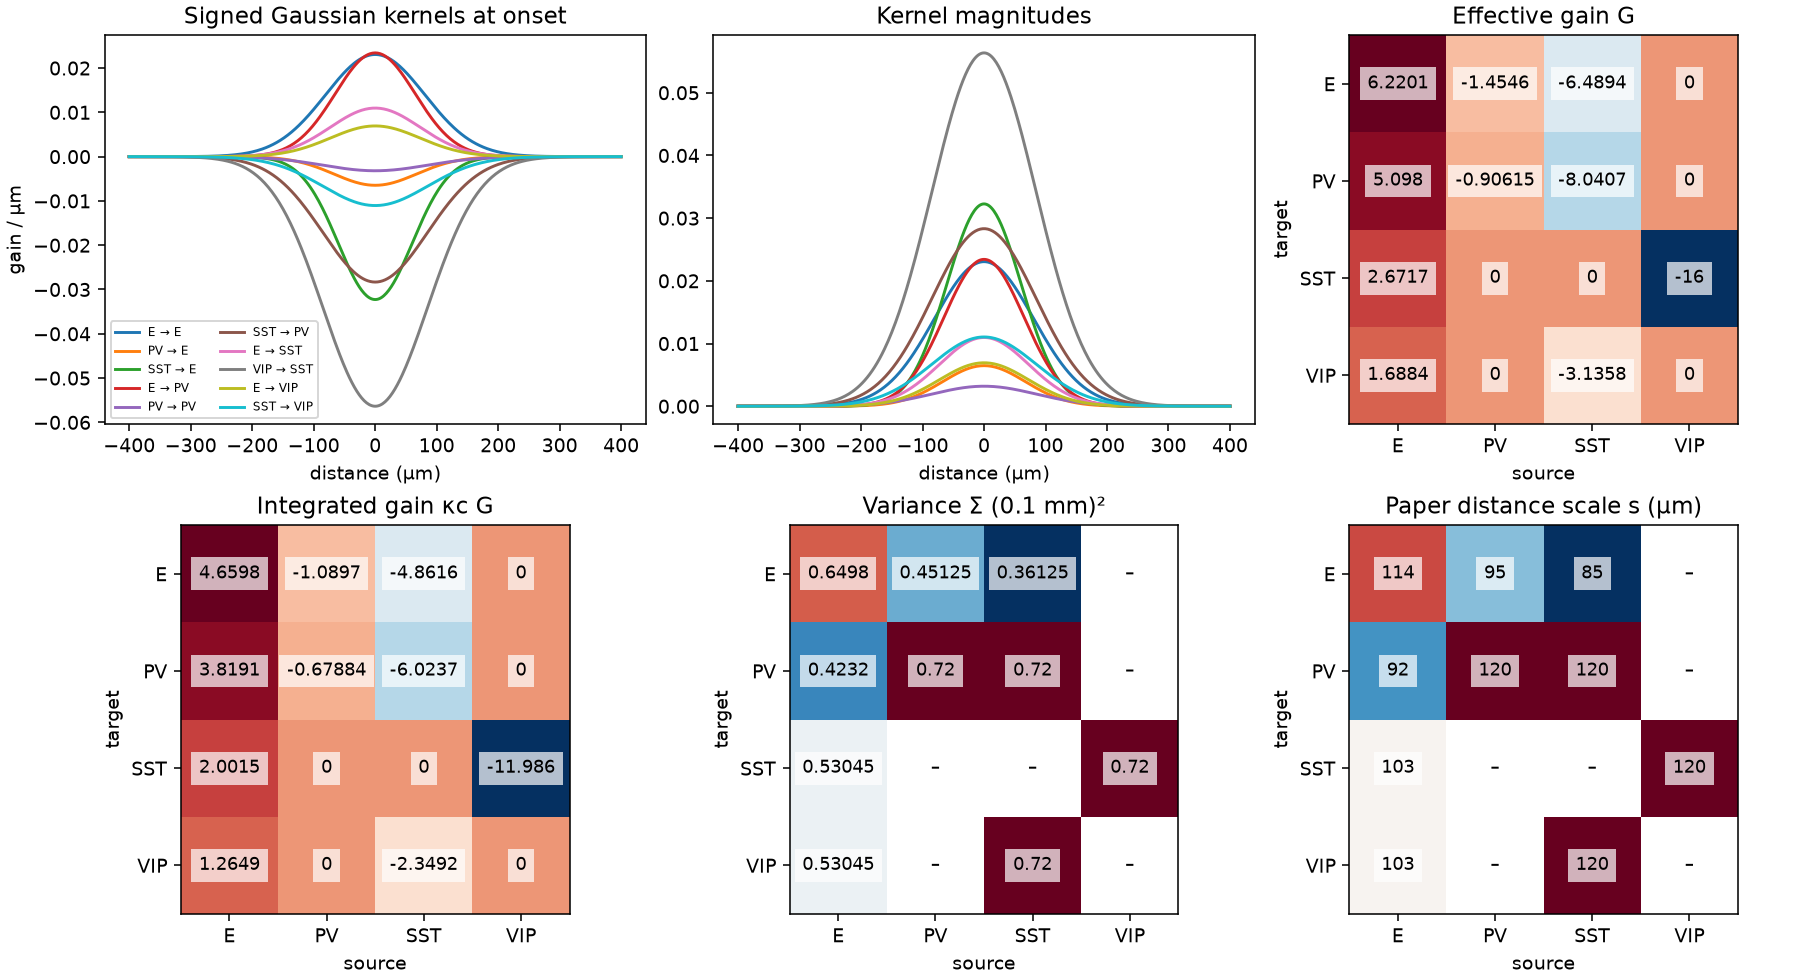

In [2]:
model,critical,normal,extra,result,summary,OUT=run_1d(K,recompute=RECOMPUTE)
def show(name): display(Image(filename=str(OUT/name)))
print('Output directory:',OUT)
show('connectivity.png')


## 2. Bifurcation and dispersion
The gray curves show all eigenvalues. The highlighted eigenvalue has maximal real
part; the positive imaginary representative is used for a conjugate pair.
Dotted vertical lines mark changes in the selected branch. The torus only admits
$q=2\pi k/L$; the continuous curve is its dispersion interpolation.


Dispersion diagnostics: {'nu_q': np.complex128(0.00022250594428866903+0.04715929643439774j), 'nu_q_physical': np.complex128(2.2250594428866903e-05+0.004715929643439774j), 'switch_brackets_rad_per_mm': [[11.120000000000001, 11.16]]}


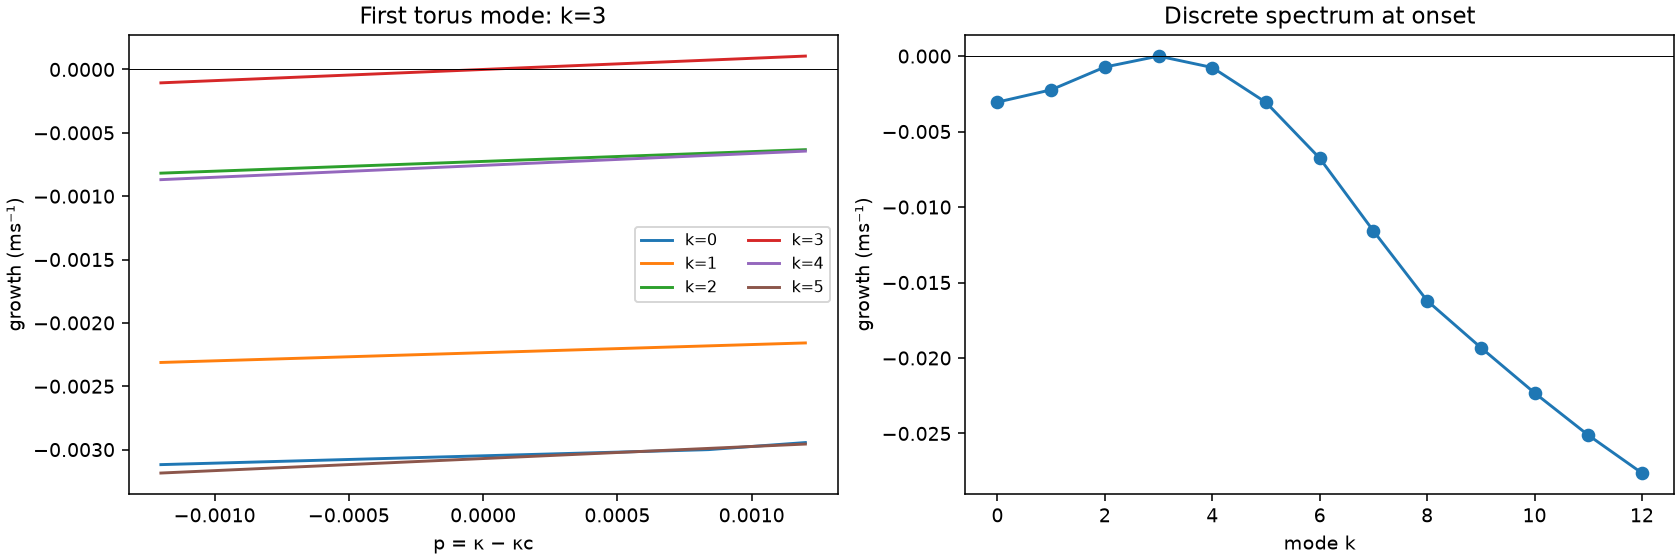

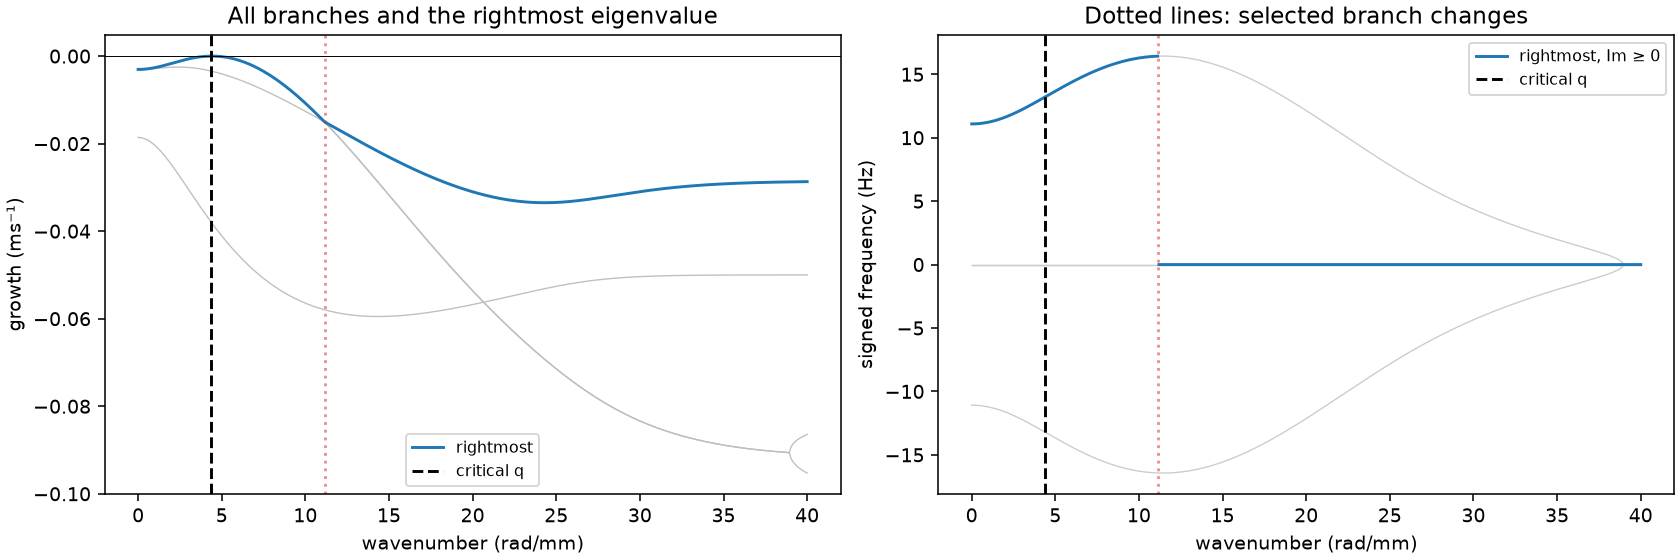

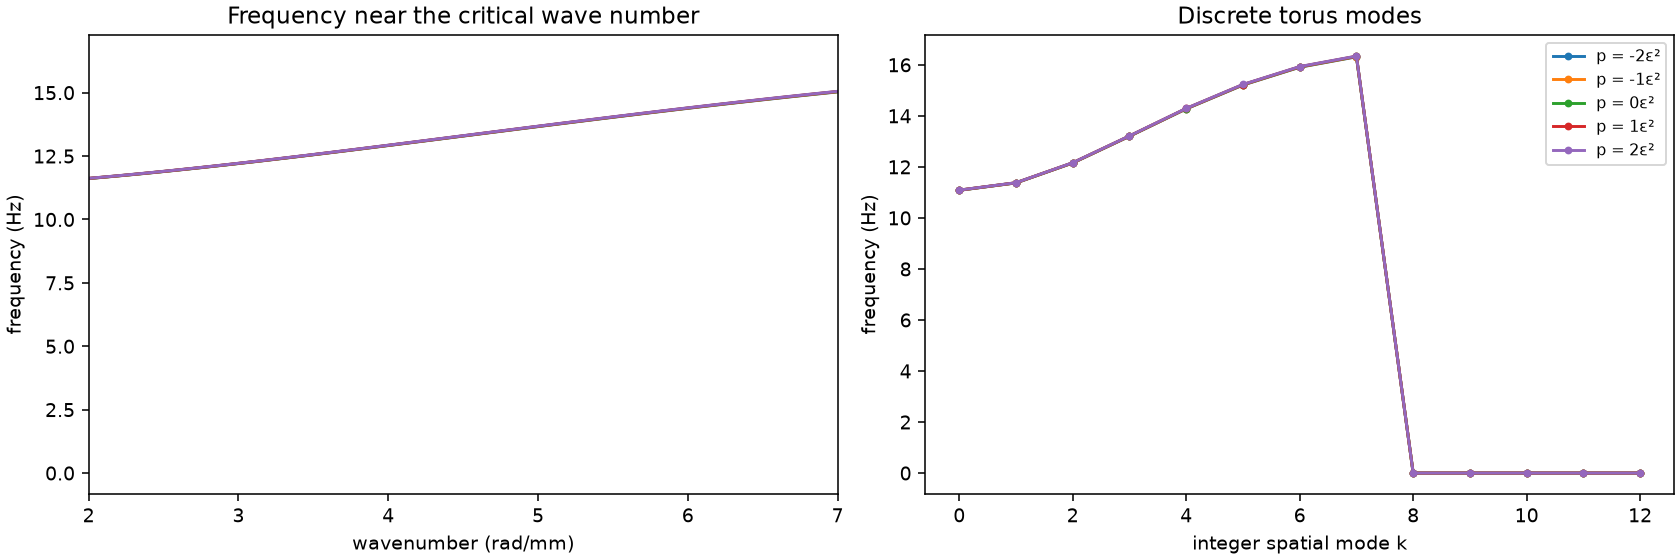

In [3]:
show('bifurcation.png')
show('dispersion.png')
show('frequency_near_onset.png')
print('Dispersion diagnostics:',summary['dispersion'])


### Increasing frequency restored
At onset, the restored model gives $d\omega/dq=+0.0471593$ rad/ms per
rad/model-length, or $+0.00471593$ mm/ms when differentiating with respect to
physical wavenumber in rad/mm. The rightmost-mode frequencies at $k=0,1,2,3,4$
are approximately $11.087,11.376,12.159,13.208,14.283$ Hz.
The increase is local and over this mode range, not a claim of global monotonicity.
All branches and changes of the rightmost branch are displayed above.

For a simple branch, with $w^*v=1$,
$$\frac{d\omega}{dq}=\Im(w^*M_qv),\qquad
M_q=-qD_\tau^{-1}\big[(\Sigma\odot\widehat W(q))D_{F'(0)}\big].$$
Changing $L$ changes the discrete wave numbers sampled, not the sign of this
derivative at a fixed $q$ and $\kappa$. Restoring the cell-pair widths and other
previous model coefficients recovers the increasing branch. At a branch switch,
use one-sided branches; a real rightmost eigenvalue has zero oscillation frequency.


## 3. Four forcing cases
The long-time panels show 100-ms RMS input/activity so that thousands of fast
cycles do not alias into apparent spatial patterns. The late zoom shows the
signed field over the final 0.5 s. The critical mode is $k_0=3$; the quadratic
harmonic is $2k_0=6$. All activity panels within each figure share a color scale.


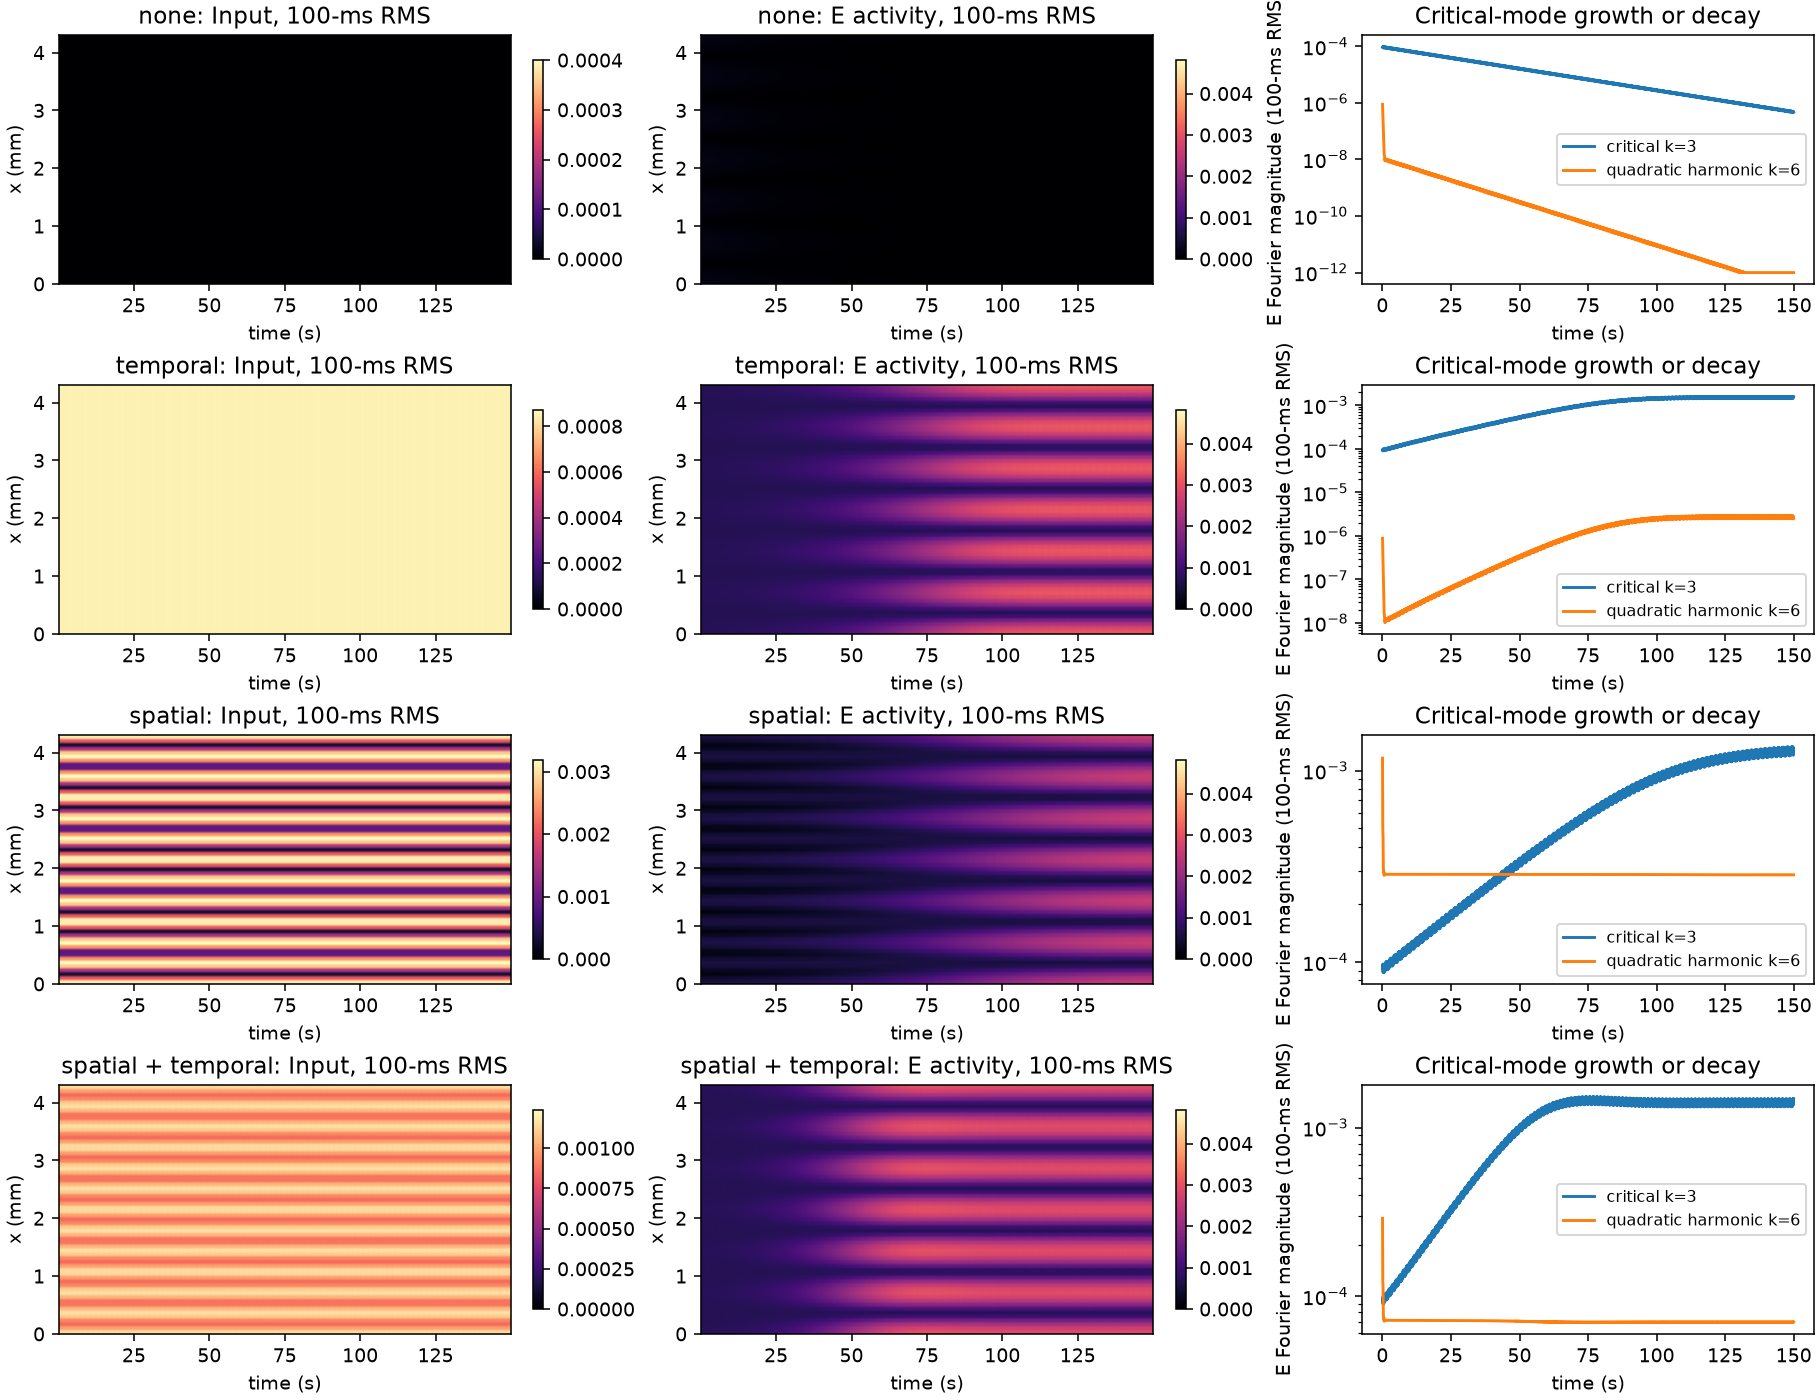

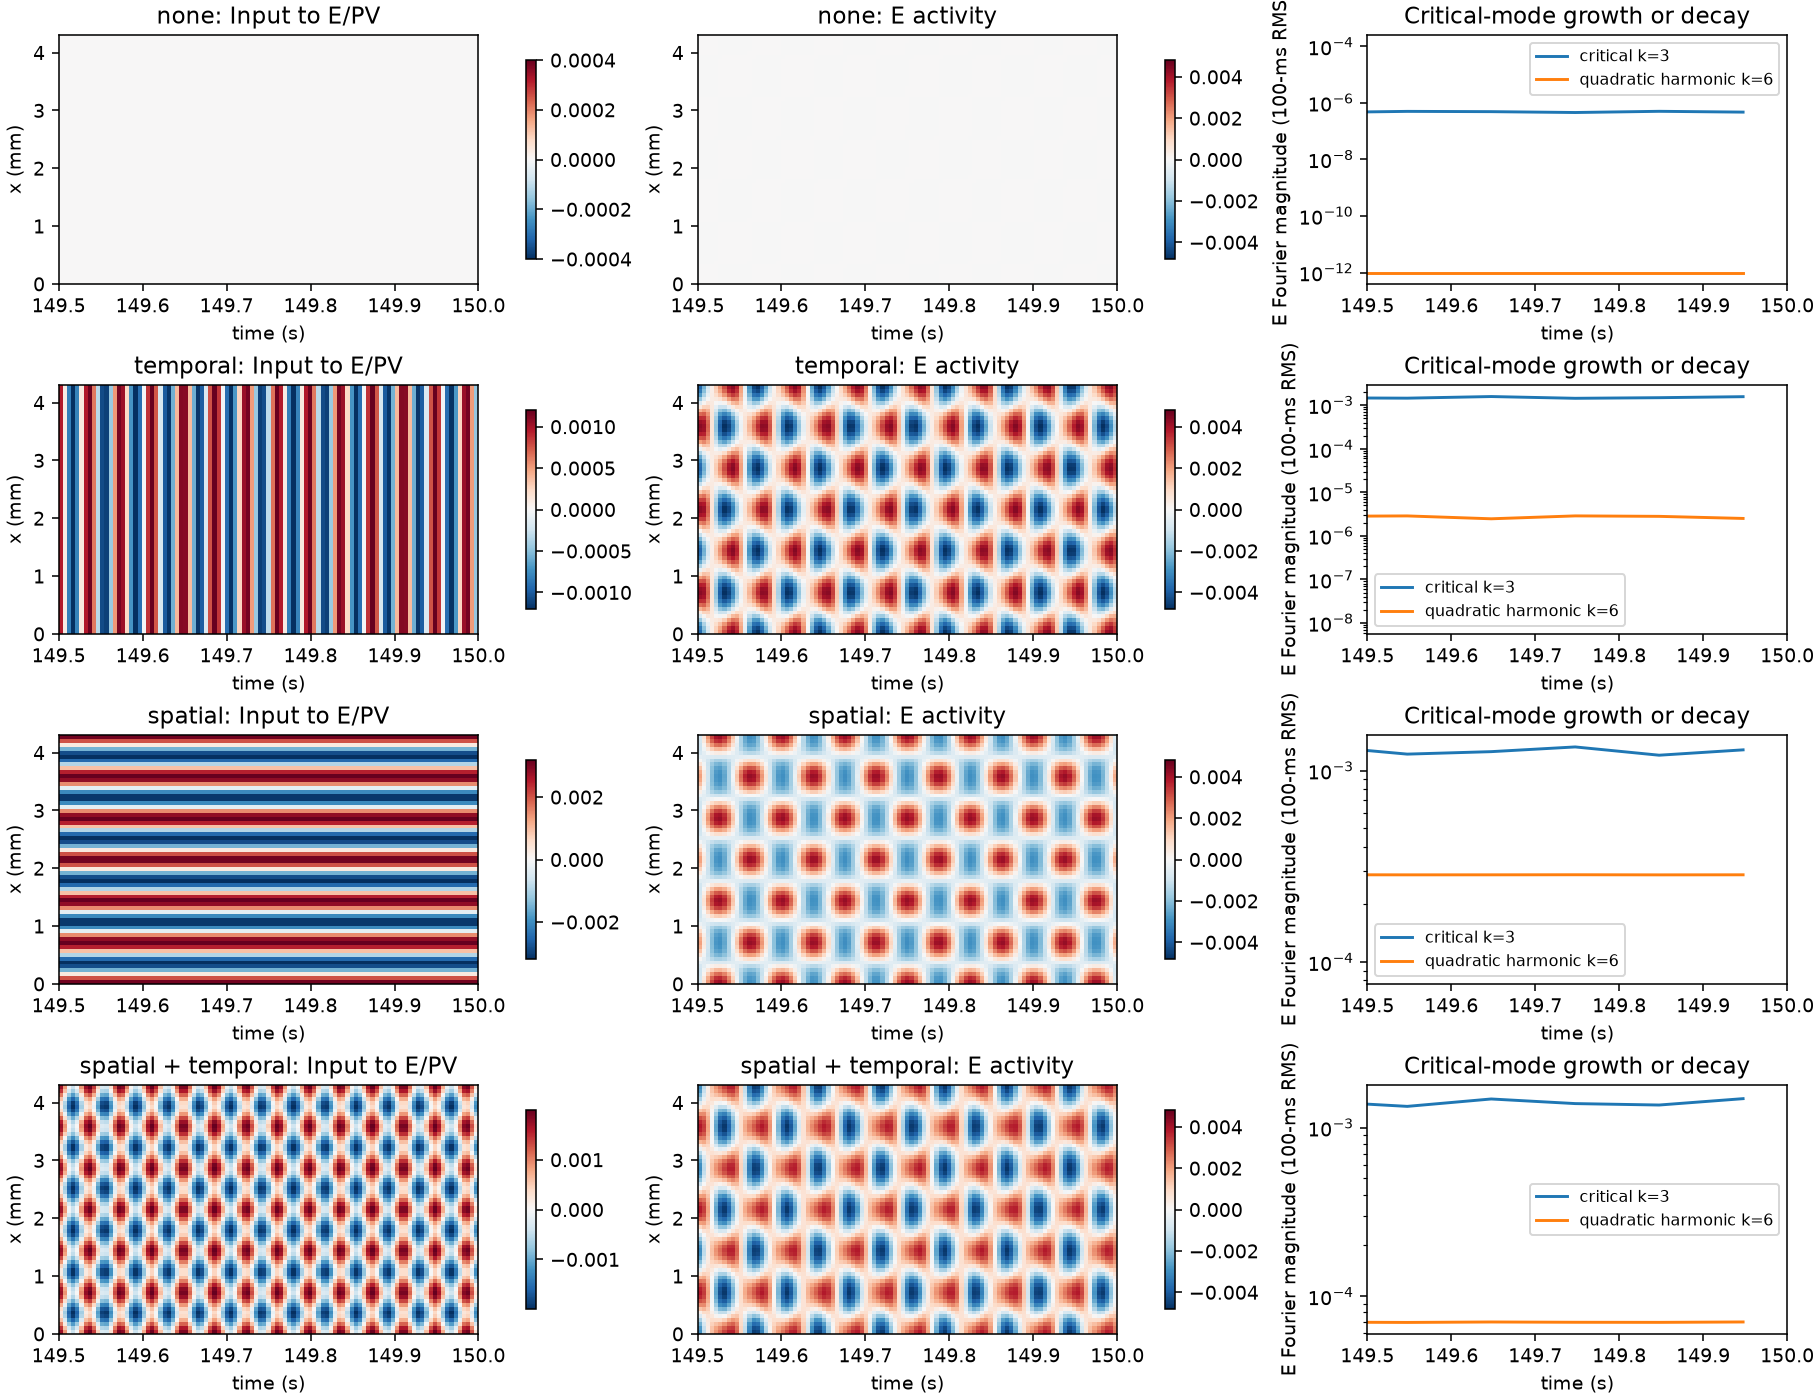

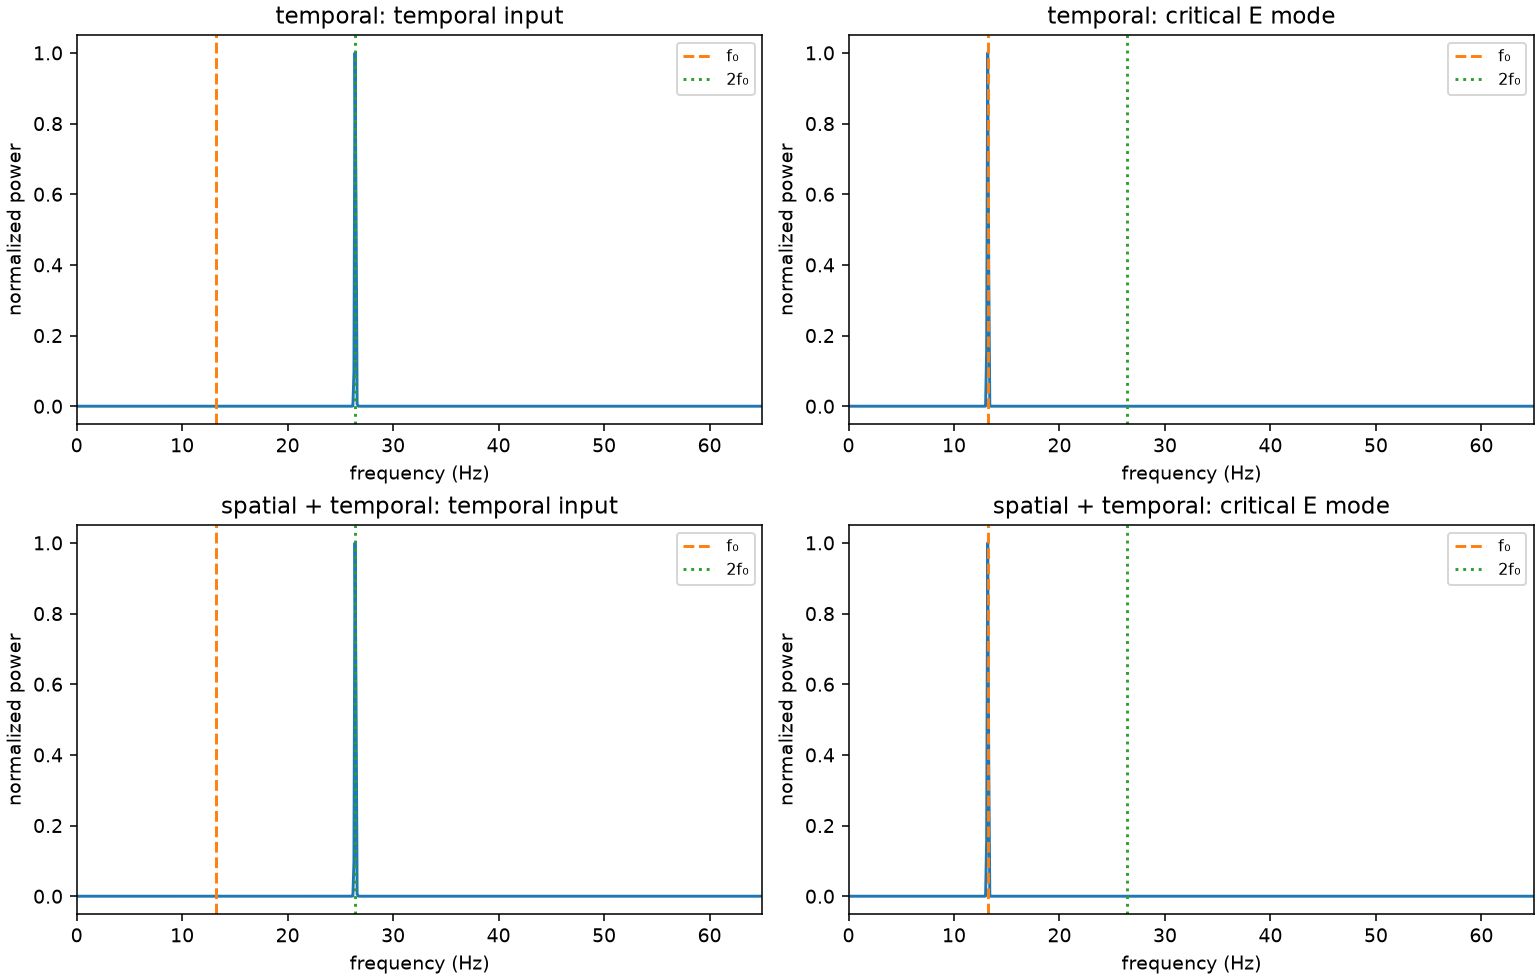

In [4]:
show('forcing_comparison.png')
show('forcing_comparison_late_zoom.png')
show('frequency_doubling_verification.png')


## 4. Detuning and weaker-forcing controls
The weak temporal case uses peak $\epsilon^2$. Detuned temporal input uses
$1.5\omega_0$ instead of $2\omega_0$; detuned spatial input uses $3k_0$ instead
of $2k_0$. The last control detunes both components. All share the same small
initial field as the resonant cases. A small directly imposed response can
remain even when the critical-mode perturbation decays.


none {'kappa': 0.7487489064741298, 'p': -0.00039999999999995595, 'critical_initial': 0.0001409400081637084, 'critical_late': 9.399889359958171e-07, 'E_mode_late_rms': 6.337855973700208e-07, 'mode_frequency_hz': 13.2, 'transverse_initial': 0.0, 'transverse_final': 0.0}
temporal {'kappa': 0.7487489064741298, 'p': -0.00039999999999995595, 'critical_initial': 0.0001409400081637084, 'critical_late': 0.00225599179154432, 'E_mode_late_rms': 0.0015033998658607775, 'mode_frequency_hz': 13.2, 'transverse_initial': 0.0, 'transverse_final': 0.0}
spatial {'kappa': 0.7487489064741298, 'p': -0.00039999999999995595, 'critical_initial': 0.0001409400081637084, 'critical_late': 0.0018747359001913568, 'E_mode_late_rms': 0.0012493319067795054, 'mode_frequency_hz': 13.2, 'transverse_initial': 0.0, 'transverse_final': 0.0}
spatial + temporal {'kappa': 0.7487489064741298, 'p': -0.00039999999999995595, 'critical_initial': 0.0001409400081637084, 'critical_late': 0.0021193834473478244, 'E_mode_late_rms': 0.00141

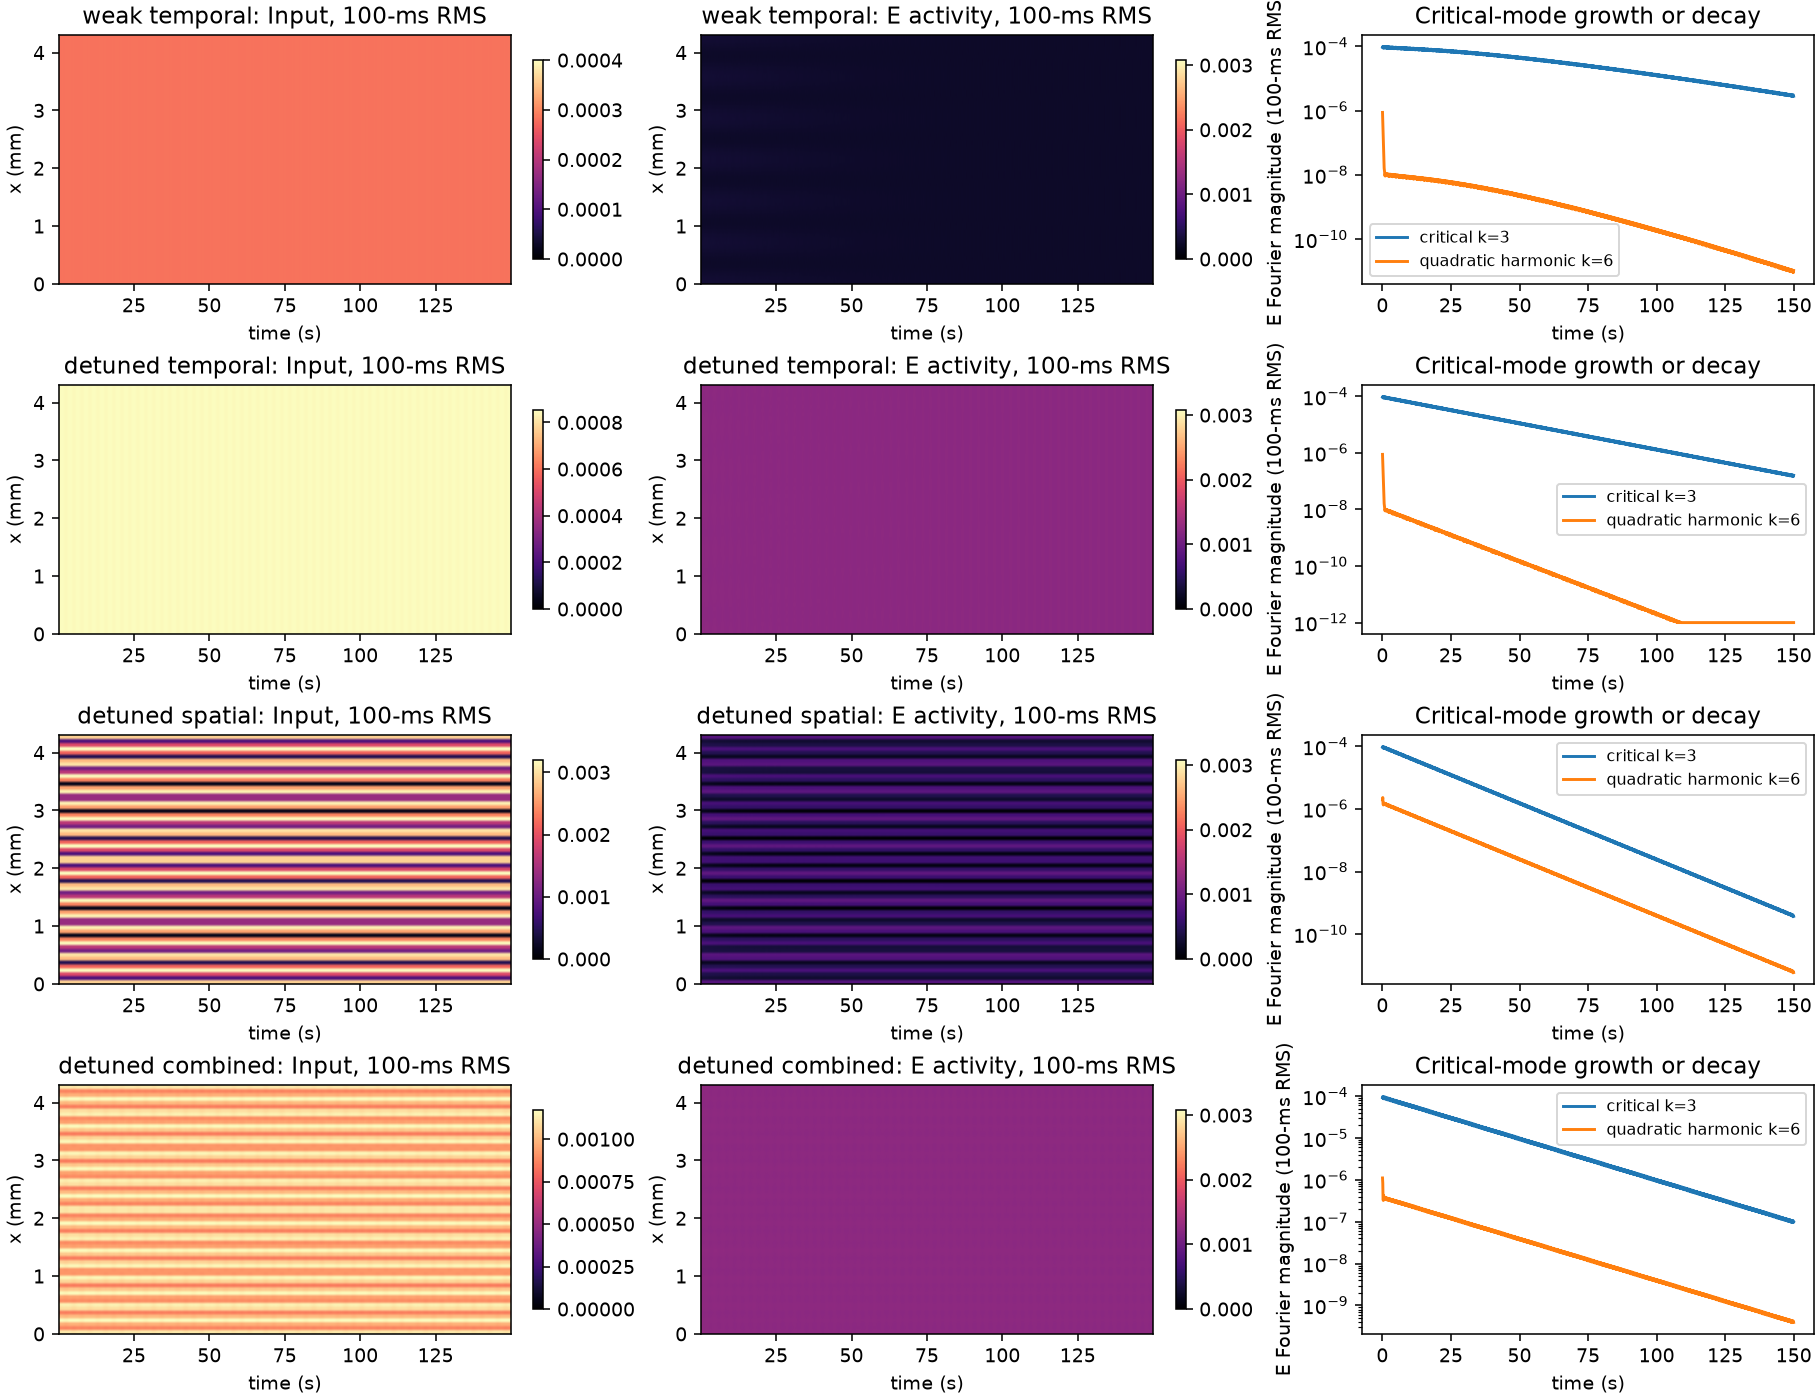

In [5]:
show('off_resonance_and_subthreshold.png')
for label in ['none','temporal','spatial','spatial + temporal','weak temporal','detuned temporal','detuned spatial','detuned combined']:
    print(label,summary['cases'][label])


### E-only versus E/PV drive
These two runs use the same temporal cosine peak $3\epsilon^2$ on E and the same
initial field. The E-only case sets the PV input to zero. Its leading temporal
threshold is approximately 0.724, compared with 1.741 for equal E/PV drive.
A difference in response amplitude reflects forcing projection onto the critical
mode, not evidence that one input pattern is biologically exclusive.


{'kappa': 0.7487489064741298, 'p': -0.00039999999999995595, 'critical_initial': 0.0001409400081637084, 'critical_late': 0.0038203074875011204, 'E_mode_late_rms': 0.0025455247916760246, 'mode_frequency_hz': 13.2, 'transverse_initial': 0.0, 'transverse_final': 0.0}


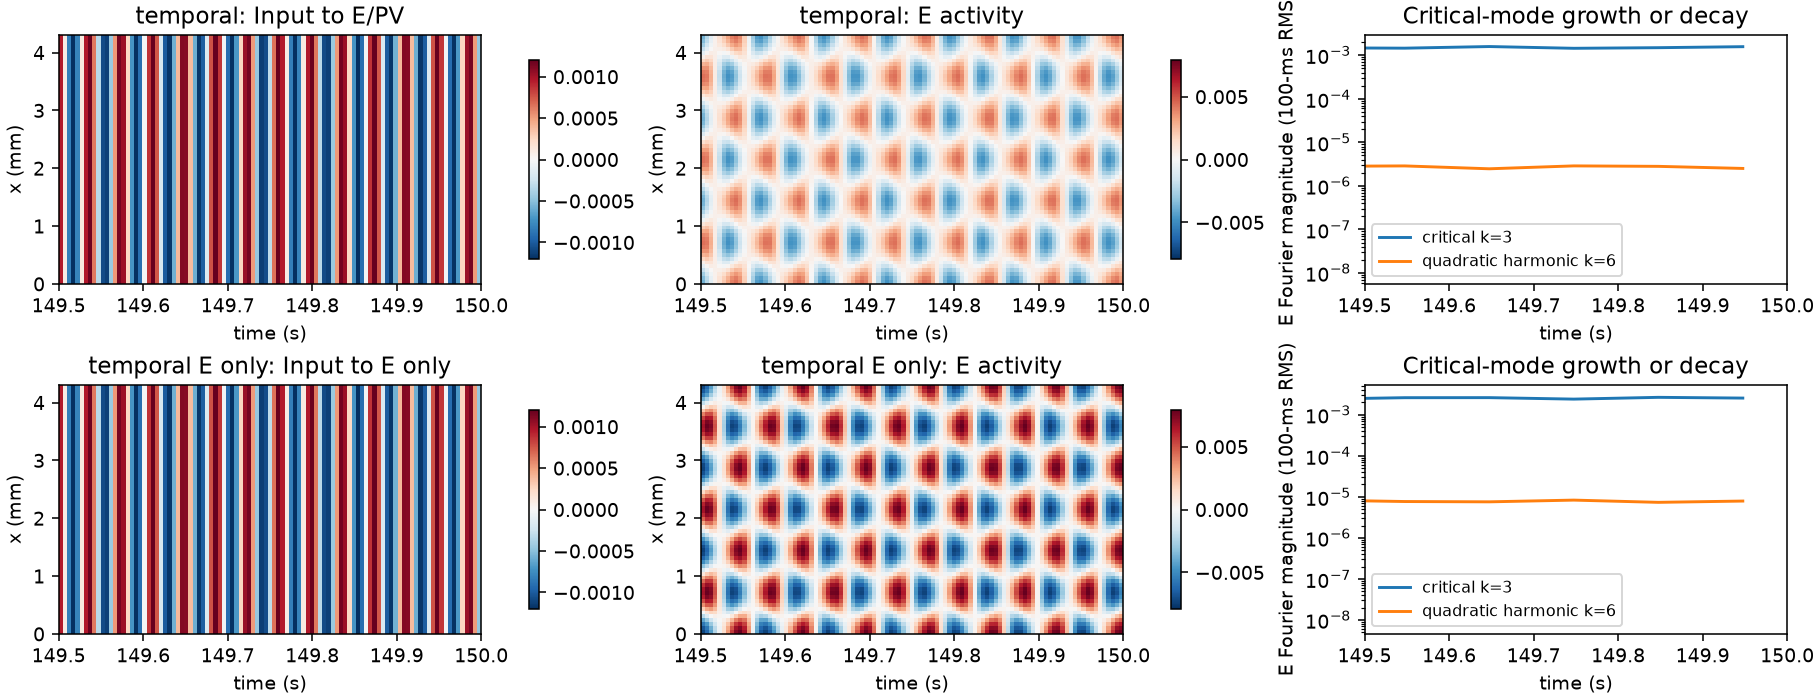

In [6]:
show('input_population_comparison.png')
print(summary['cases']['temporal E only'])


## 5. Unforced homogeneous, standing and traveling patterns
The branch diagram is the cubic prediction. With the current coefficients the
unforced traveling branch is stable at cubic order; the standing branch is
unstable to an imbalance of its two counterpropagating amplitudes.
The ideal-pattern panels are analytic illustrations.

The direct runs use $p=-\epsilon^2$ for the below-onset case and $p=+\epsilon^2$
for both above-onset cases. An exactly reflection-symmetric standing seed
preserves the standing-wave subspace; it does **not** establish stability to
general perturbations. A traveling seed tests the traveling branch. These
unforced statements are distinct from the forced standing-wave stability result.


below onset {'kappa': 0.7487489064741298, 'p': -0.00039999999999995595, 'critical_initial': 0.0001409400081637084, 'critical_late': 9.399889359958171e-07, 'E_mode_late_rms': 6.337855973700208e-07, 'mode_frequency_hz': 13.2, 'transverse_initial': 0.0, 'transverse_final': 0.0}
standing seed above onset {'kappa': 0.7495489064741298, 'p': 0.00039999999999995595, 'critical_initial': 0.0001414213562373095, 'critical_late': 0.0022160932850322722, 'E_mode_late_rms': 0.0014764650610996925, 'mode_frequency_hz': 13.2, 'transverse_initial': 0.0, 'transverse_final': 0.0}
traveling seed above onset {'kappa': 0.7495489064741298, 'p': 0.00039999999999995595, 'critical_initial': 0.00020000000000000004, 'critical_late': 0.002241057396140397, 'E_mode_late_rms': 0.0014935752723446256, 'mode_frequency_hz': 13.2, 'transverse_initial': 0.0, 'transverse_final': 0.0}


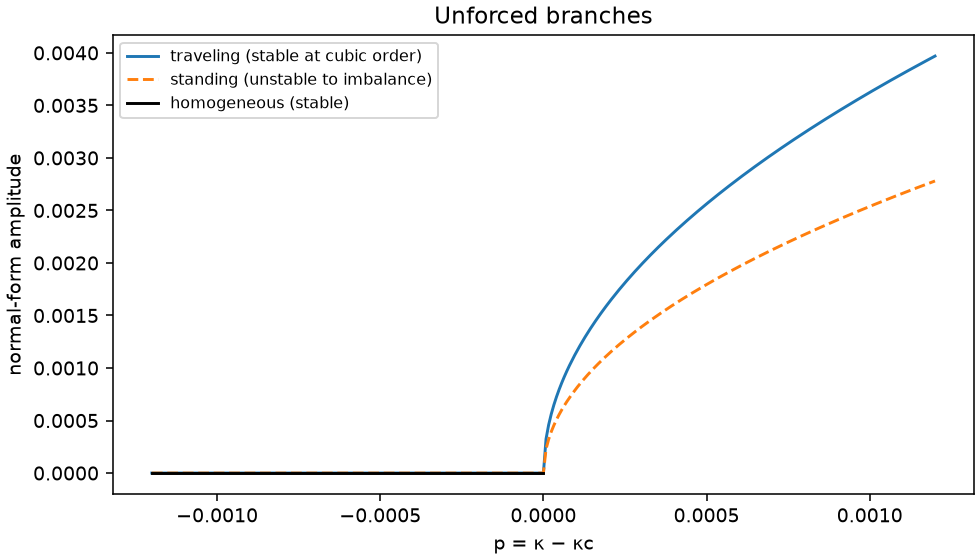

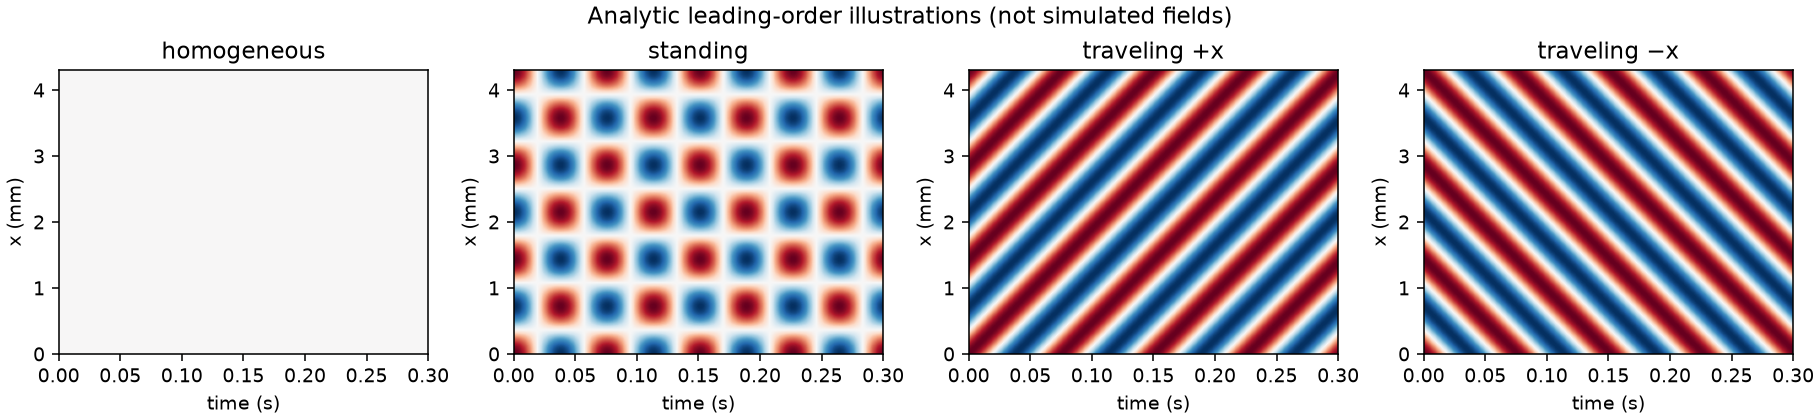

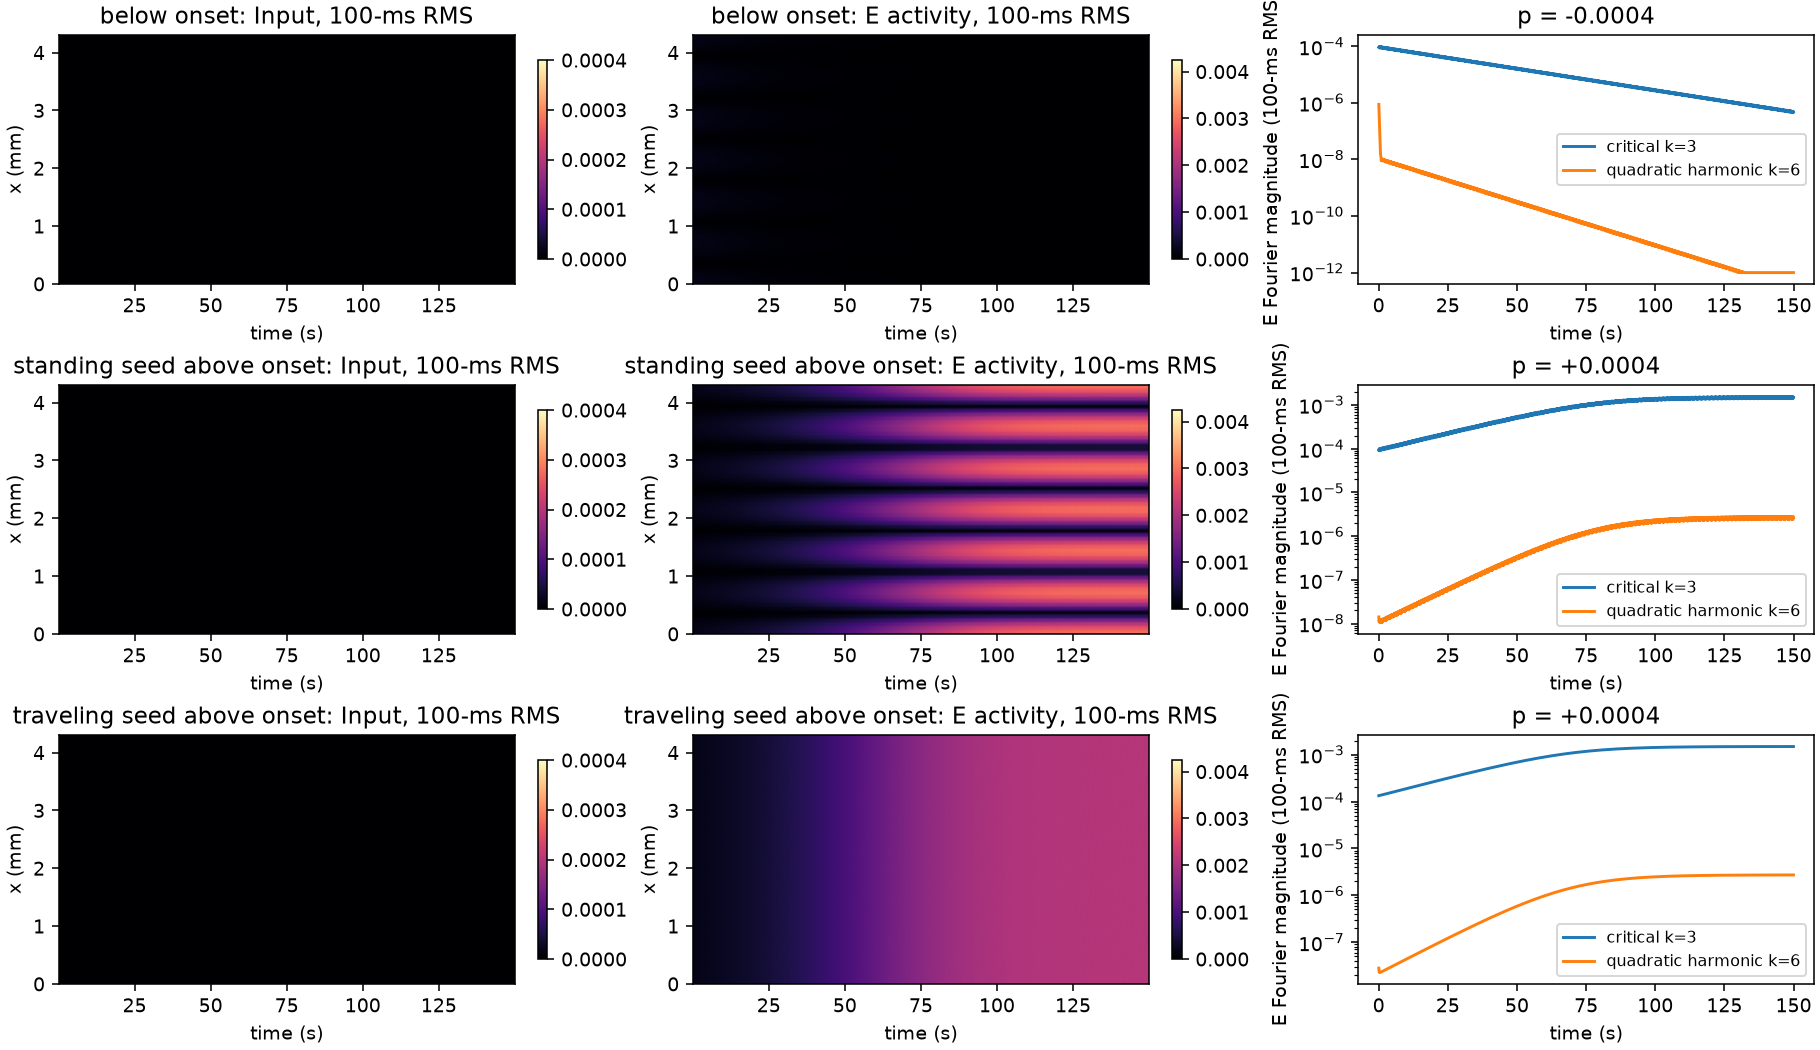

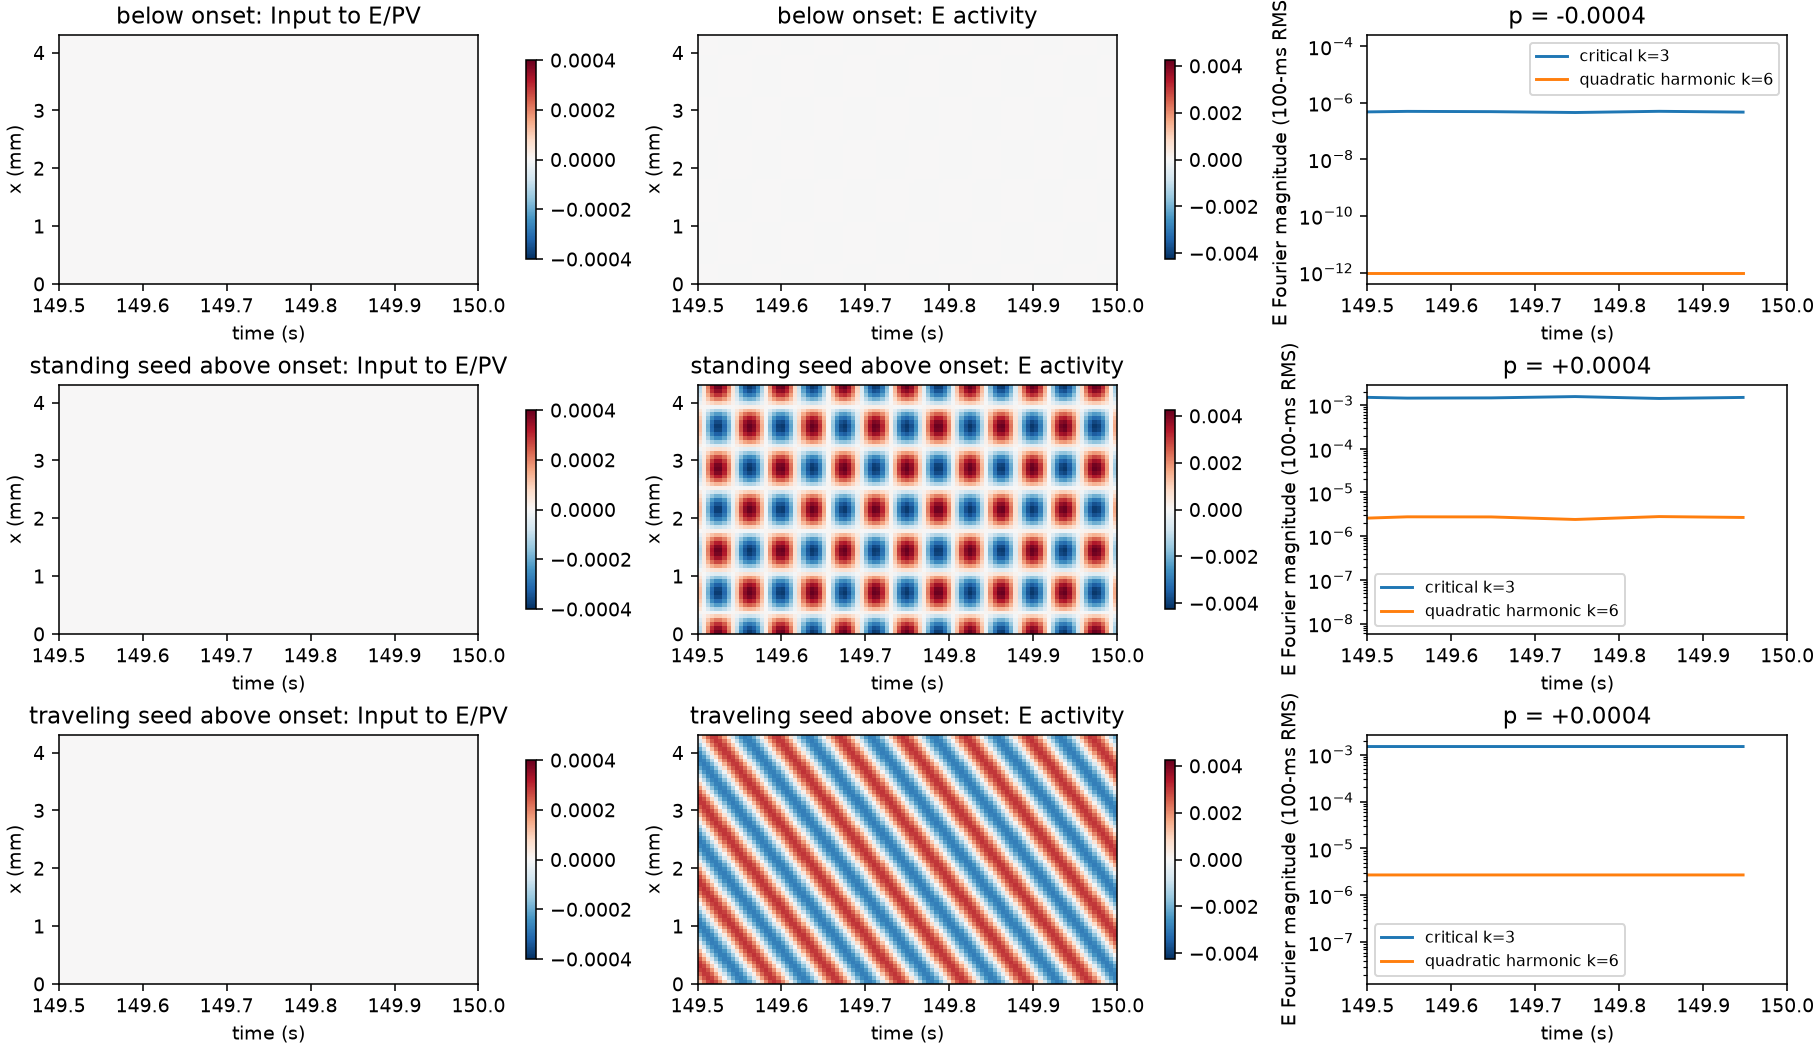

In [7]:
show('normal_form_branches.png')
show('ideal_wave_patterns.png')
show('unforced_parameter_sweep.png')
show('unforced_parameter_sweep_late_zoom.png')
for label in ['below onset','standing seed above onset','traveling seed above onset']:
    print(label,summary['cases'][label])


## 6. All-population late-time fields
Select a case below. Activities remain dimensionless; coordinates are shown in mm and seconds.

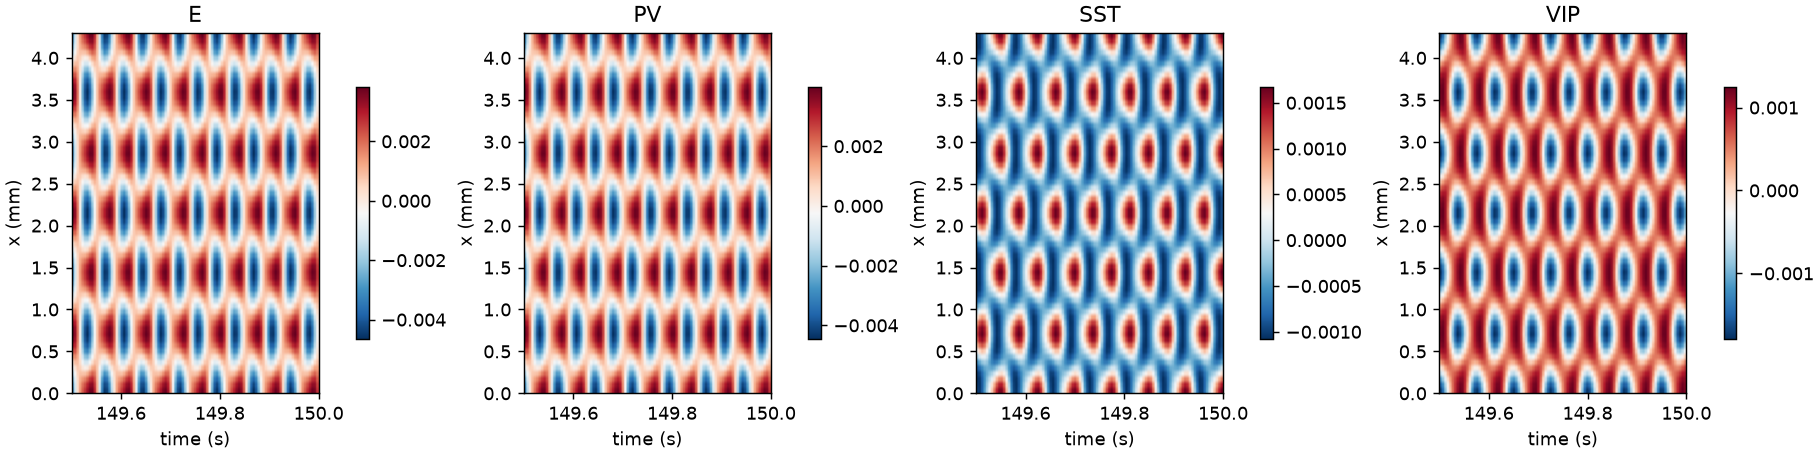

In [8]:
SELECT_CASE='spatial + temporal'
j=list(result['labels']).index(SELECT_CASE)
keep=result['snapshot_t']>=result['snapshot_t'][-1]-500
u=result['snapshots'][keep,j]
fig,axs=plt.subplots(1,K,figsize=(3.5*K,3.5),layout='constrained',squeeze=False)
for pop,ax in enumerate(axs[0]):
    image=ax.imshow(u[:,pop].T,origin='lower',aspect='auto',extent=[result['snapshot_t'][keep][0]/1000,result['snapshot_t'][-1]/1000,0,model.length*.1],cmap='RdBu_r')
    ax.set(title=model.names[pop],xlabel='time (s)',ylabel='x (mm)')
    fig.colorbar(image,ax=ax,shrink=.7)
showfig(fig)


## 7. Three-population model (E/PV/SST)
**Connectivity.** Widths, relaxation times, activation parameters, signs and zeros are the
E/PV/SST block of the four-population model. With the unchanged gains the first
instability is homogeneous ($k=0$, $\kappa_c\approx0.65373$), so the finite-wave amplitude
equations do not apply. A single-entry scan (±10% of each nonzero gain, same sign) shows that
only strengthening E→E moves the first crossing to a nonzero wave number. We therefore use
$$G^{(3)}=\begin{pmatrix}6.72&-1.45455&-6.48944\\5.09798&-0.90615&-8.04066\\2.67174&0&0\end{pmatrix},
\qquad G^{(3)}_{EE}=6.72=1.0804\times6.22009 .$$
All other entries equal the four-population values. `make_model(3, submatrix=True)` returns the
unmodified block.

**Onset.** $\kappa_c$, $k_0$, $\omega_0$ and the normal-form coefficients are recomputed exactly as
for four populations (first modal crossing of $J=\kappa G^{(3)}$). On the 1D torus with $L=43$ the
first crossing is the Hopf mode $k_0=3$. On the square torus the oblique shell $|k|^2=8$ crosses
slightly earlier, so this model is analyzed in 1D only; the audit below checks the 1D mode lattice.


In [9]:
K3=3
model3=make_model(K3)
critical3,normal3,extra3=coefficients(model3)
checks3=model_audit(K3,model3,critical3,normal3,extra3)
print('Populations:',model3.names)
print('G (E->E strengthened; all other entries from the 4-population matrix):\n',model3.A_p)
block=make_model(3,submatrix=True).A_p
print('Changed entries (target, source, submatrix value, used value, relative change):')
for i,j in zip(*np.nonzero(model3.A_p!=block)):
    print(' ',model3.names[i],model3.names[j],block[i,j],model3.A_p[i,j],f'{model3.A_p[i,j]/block[i,j]-1:+.2%}')
print(f'Periodic onset: kappa_c={critical3.p0:.12f}, k0={critical3.mode}, f0={critical3.frequency_hz:.6f} Hz')
print('alpha, b, c (1/ms):',normal3.alpha,normal3.b,normal3.c)
print('c_perp (1/ms):',extra3['c_perp'])
print('eta_t, eta_x per unit peak (1/ms):',extra3['eta_t_unit'],extra3['eta_x_unit'])
print(f"d omega/dq at q0: {extra3['nu_q'].imag:.7f} (model units) = {.1*extra3['nu_q'].imag:.8f} mm/ms")
print('1D spectral/stability checks:',checks3)


Populations: ('E', 'PV', 'SST')
G (E->E strengthened; all other entries from the 4-population matrix):
 [[ 6.72    -1.45455 -6.48944]
 [ 5.09798 -0.90615 -8.04066]
 [ 2.67174  0.       0.     ]]
Changed entries (target, source, submatrix value, used value, relative change):
  E E 6.22009 6.72 +8.04%
Periodic onset: kappa_c=0.588034165663, k0=3, f0=9.540771 Hz
alpha, b, c (1/ms): (0.08665736136649413+0.03560858901401061j) (-3.412555132250863+1.8288718196157354j) (-3.4056279476068307+1.6730415558987912j)
c_perp (1/ms): (-3.439064931470434+1.7118233016013422j)
eta_t, eta_x per unit peak (1/ms): (0.038522686198754534-0.04866317171134894j) (-0.003255047151742345+0.054558002734123874j)
d omega/dq at q0: 0.0404988 (model units) = 0.00404988 mm/ms
1D spectral/stability checks: {'square_spectral_gap': np.float64(0.0002783955420715793), 'tail_row_sum_bound': np.float64(2.0991928879932792e-05), 'temporal_threshold': 1.5095093441141727, 'traveling_threshold': 0.7941517243575609, 'spatial_threshold

### Forcing peaks for three populations
The cases use **the same peaks as for four populations**, $(0,0),(3,0),(0,8),(3,2)$ in units of
$\epsilon^2$ (temporal, spatial), with $\epsilon=0.02$, $p=-\epsilon^2$ and equal E/PV input, so the
two models see identical input. The thresholds are this model's own:

- Temporal: $|\alpha|/|\eta_t^{\rm unit}|\approx1.51$. Peak 3 exceeds it and the weak control 1 is below it.
- Spatial: $\Re\eta_x^{\rm unit}<0$, so real spatial input destabilizes the standing branch $A=-B$
  rather than $A=B$. On $A=\sigma B$, $z_\tau=z(a+\sigma\eta_x+\gamma|z|^2)+\sigma\eta_t\bar z$ with
  $\sigma=\operatorname{sign}\Re\eta_x$. Its threshold is $\Re\alpha/|\Re\eta_x^{\rm unit}|\approx26.6$,
  so **spatial peak 8 is below threshold** and the spatial-only case is expected to decay.
- Combined (3,2) satisfies the standing-wave stability inequalities with $\eta_x\to\sigma\eta_x$.
  Its zero-state growth is only $\approx1.5\times10^{-5}$ ms$^{-1}$. The three-population runs therefore last
  **300 s** ($\epsilon^2t=120$) instead of 150 s, so that this case saturates.

The standing seed is shifted by a quarter wavelength ($\sin k_0x$), which is the $A=-B$ pattern.
All other numerical settings equal the four-population runs.

**Why not a spatial peak above 26.6?** $\Re\eta_x^{\rm unit}=-0.0033$ is small compared with
$\Im\eta_x^{\rm unit}=0.055$. A peak of order $30\epsilon^2$ makes the neglected $O((\delta\epsilon^2)^2)$
terms larger than the $O(\delta\epsilon^2\Re\eta_x)$ term that sets the threshold. The next cell
computes the forced steady state of the full 1D field for a time-independent input
$\delta\epsilon^2(1,1,0)^T\cos2q_0x$ and the leading eigenvalue of its Jacobian. Without input
the two agree. At peak 8 both are negative, with the field somewhat more stable. Beyond the
predicted threshold the amplitude equation predicts growth, but the field becomes *more* stable,
so spatial-only forcing does not create the pattern at $\epsilon=0.02$ in this model.


In [10]:
from scipy.optimize import fsolve
from scipy.special import expit
def forced_state_growth(m,cr,delta,n=64):
    K=m.K;kappa=cr.p0-EPS**2;x=(np.arange(n)+.5)*m.length/n
    q=2*np.pi*np.fft.fftfreq(n,d=m.length/n)
    sym=m.connectivity(kappa)[:,:,None]*np.exp(-m.Sigma[:,:,None]*q**2/2)
    g,th,tau=m.gain[:,None],m.theta[:,None],m.tau[:,None];off=expit(-g*th)
    I=delta*EPS**2*np.array(m.metadata['drive_weights'])[:,None]*np.cos(2*cr.q*x)[None]
    def rhs(u):return (-u+np.fft.ifft(np.einsum('ijz,jz->iz',sym,np.fft.fft(expit(g*(u-th))-off,axis=1)),axis=1).real+I)/tau
    u=fsolve(lambda v:rhs(v.reshape(K,n)).ravel(),np.zeros(K*n),xtol=1e-14).reshape(K,n)
    h=1e-7;f0=rhs(u).ravel();J=np.empty((K*n,K*n))
    for i in range(K*n):
        v=u.ravel().copy();v[i]+=h;J[:,i]=(rhs(v.reshape(K,n)).ravel()-f0)/h
    return np.linalg.eigvals(J).real.max()
sig=checks3['spatial_branch_sign']
print(f"{'peak':>5s} {'field Re lambda':>16s} {'amplitude eq. (A=sigma B)':>26s}")
for delta in [0,8,27,45]:
    pred=EPS**2*(-normal3.alpha+sig*delta*extra3['eta_x_unit']).real
    print(f'{delta:5d} {forced_state_growth(model3,critical3,delta):16.3e} {pred:26.3e}')


 peak  field Re lambda  amplitude eq. (A=sigma B)
    0       -3.468e-05                 -3.466e-05
    8       -3.809e-05                 -2.425e-05
   27       -1.565e-04                  4.916e-07
   45       -4.070e-04                  2.393e-05


Loaded matching run: /home/claude/mcn/simulations/output/main_literature/3pop_1d/field_periodic.npz
Output directory: /home/claude/mcn/simulations/output/main_literature/3pop_1d
Dispersion diagnostics: {'nu_q': np.complex128(-0.003606849173695191+0.04049882481644231j), 'nu_q_physical': np.complex128(-0.0003606849173695191+0.004049882481644232j), 'switch_brackets_rad_per_mm': [[16.6, 16.64]]}


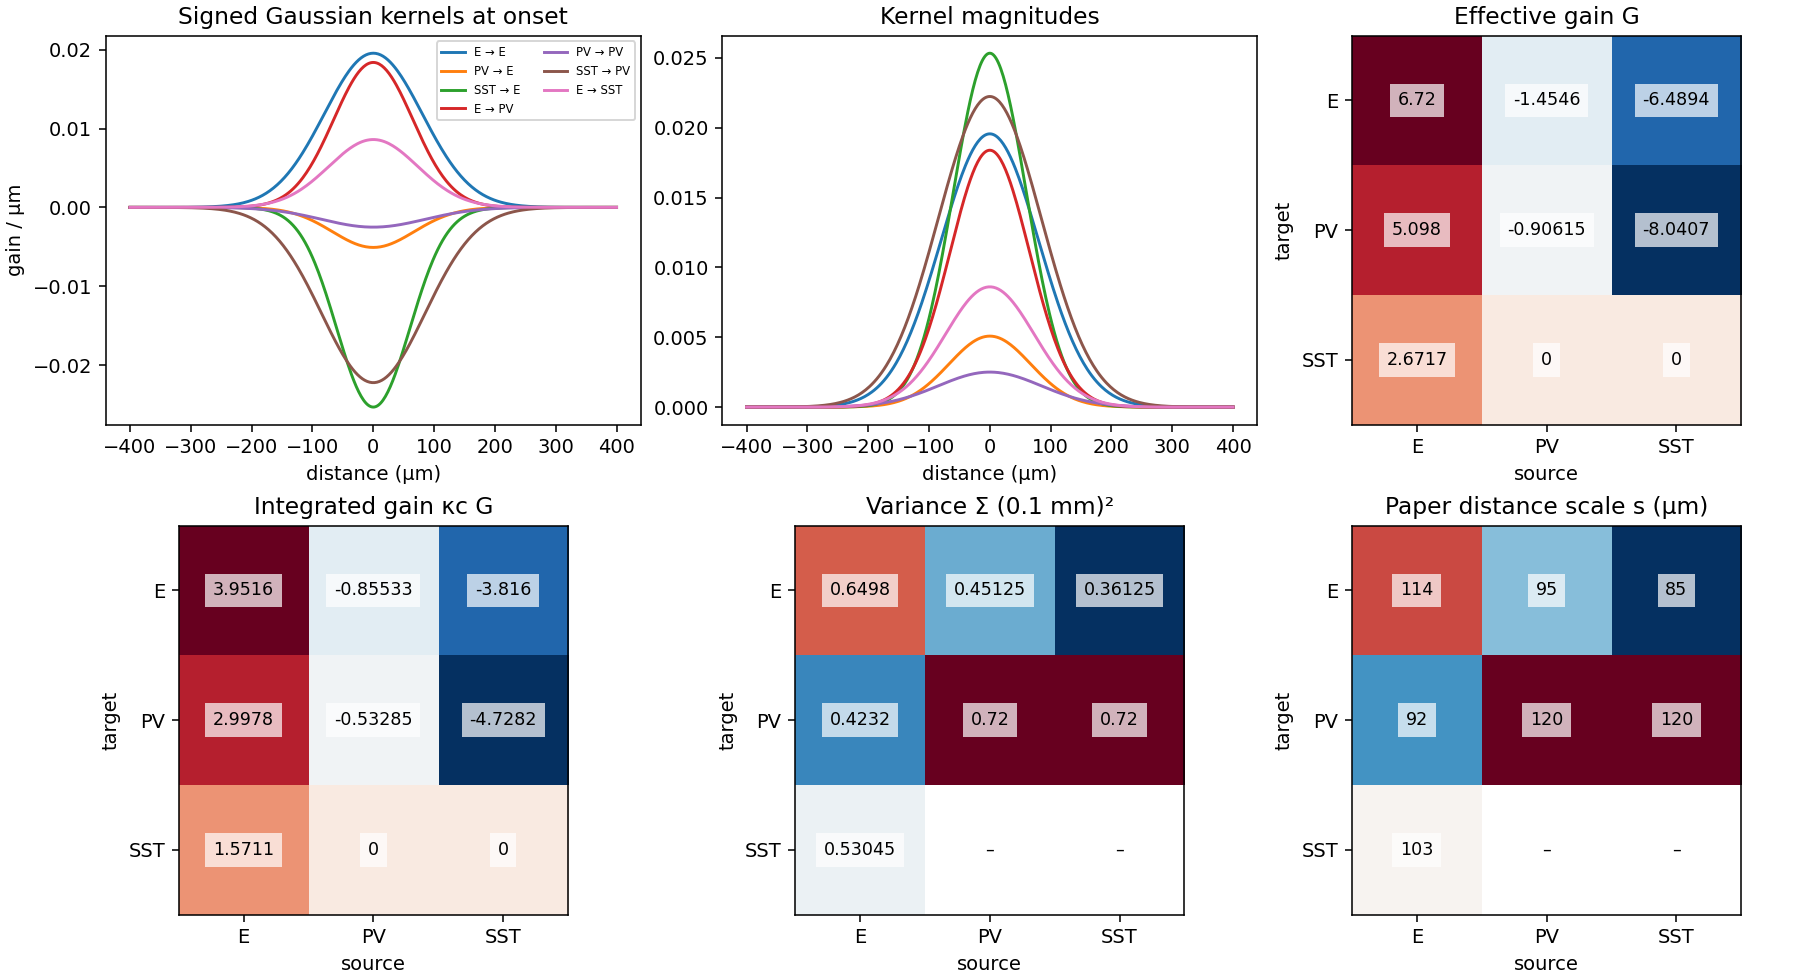

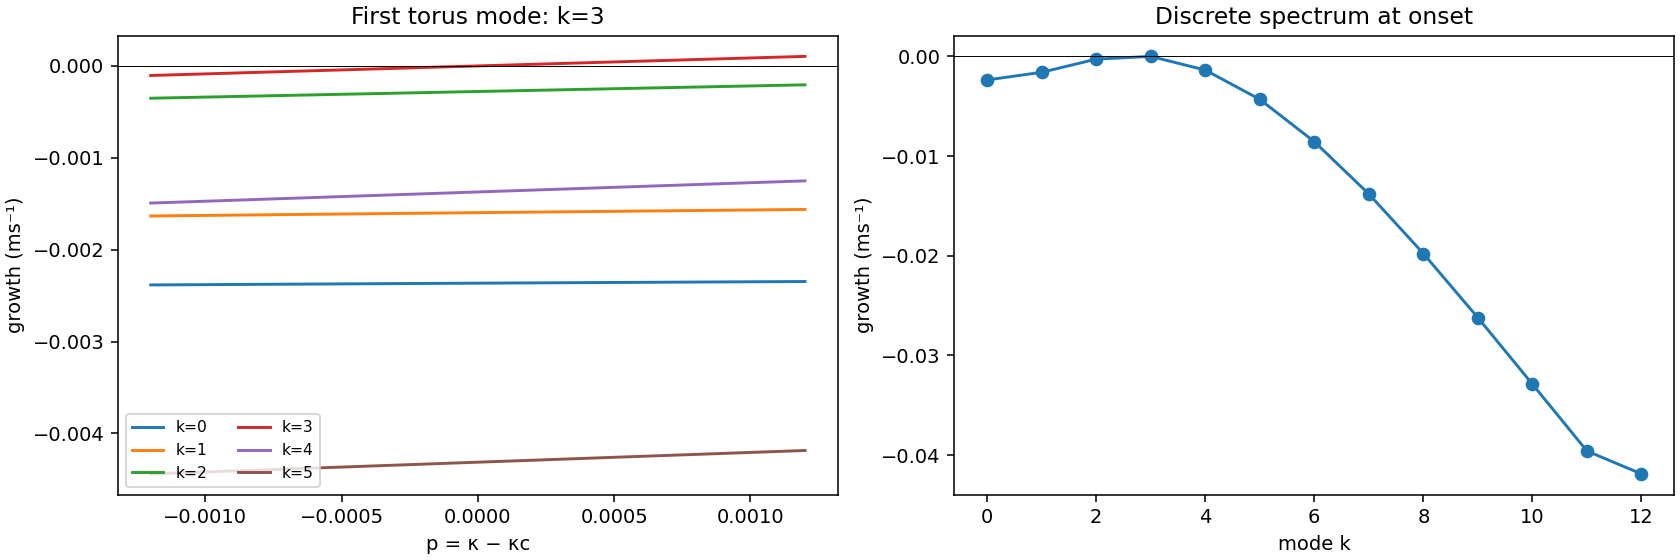

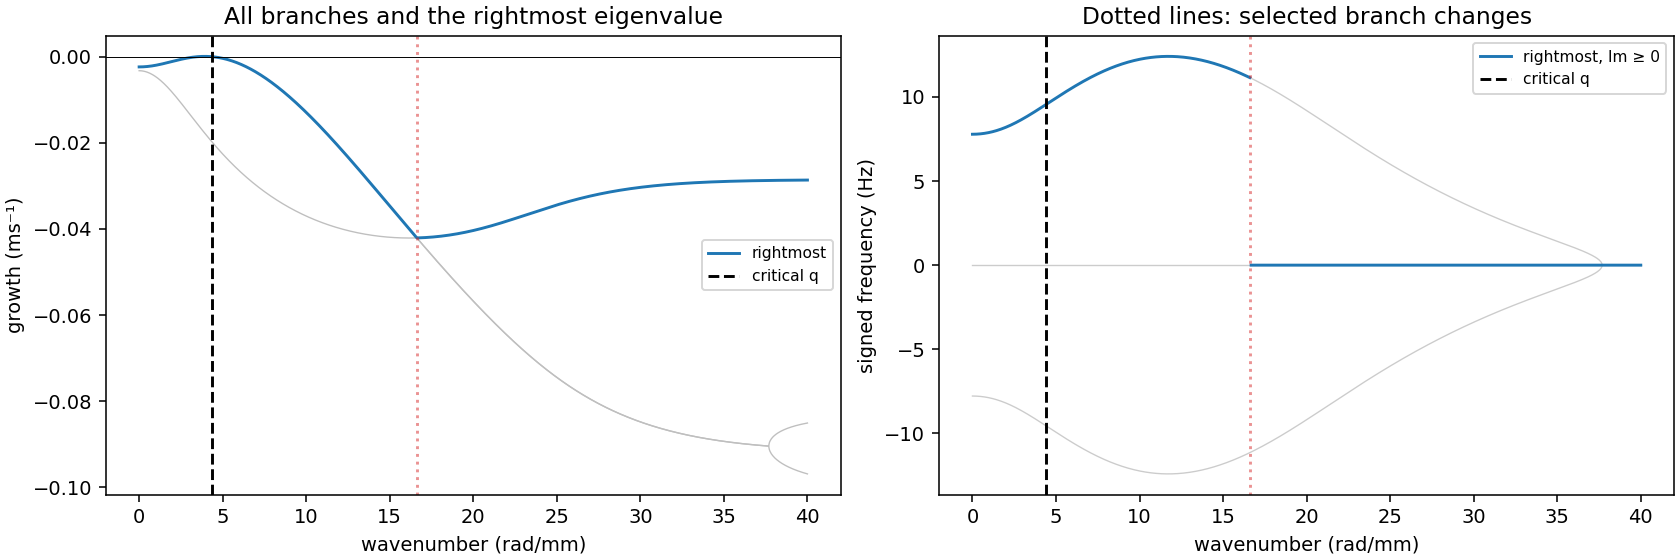

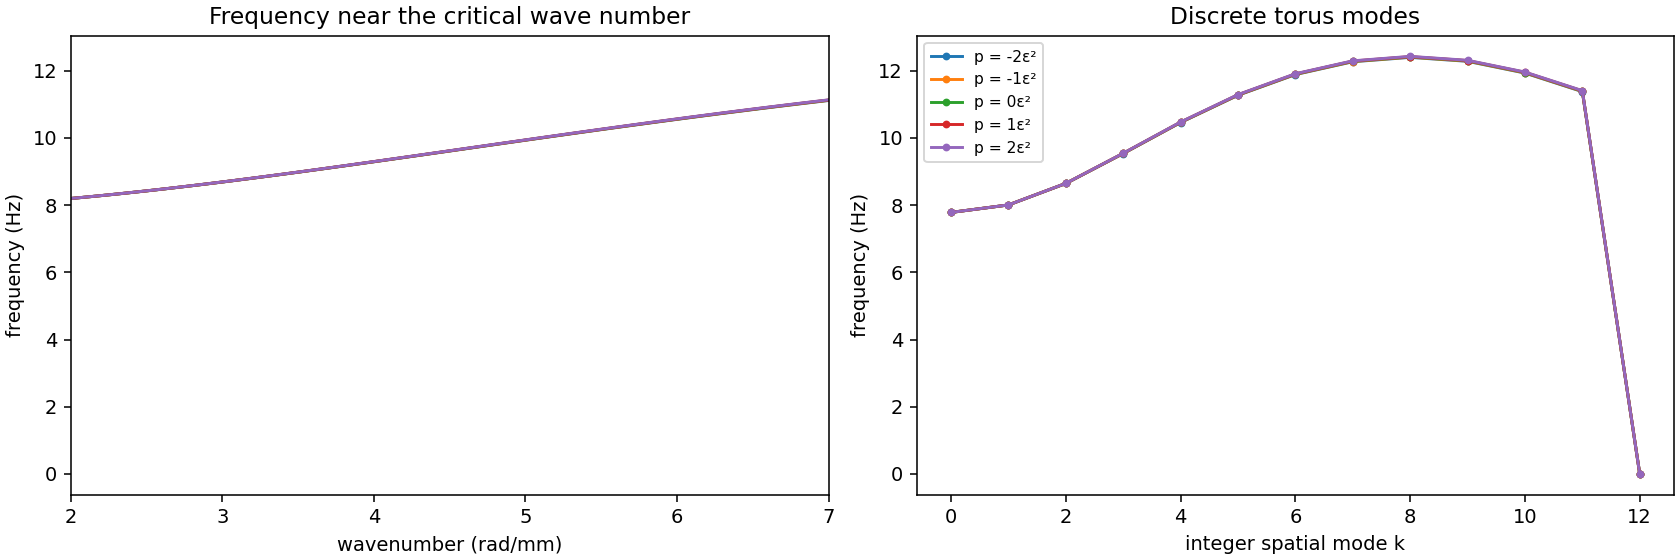

In [11]:
model3,critical3,normal3,extra3,result3,summary3,OUT3=run_1d(K3,recompute=RECOMPUTE)
def show3(name): display(Image(filename=str(OUT3/name)))
print('Output directory:',OUT3)
show3('connectivity.png')
show3('bifurcation.png')
show3('dispersion.png')
show3('frequency_near_onset.png')
print('Dispersion diagnostics:',summary3['dispersion'])


### Four forcing cases, controls and E-only input
Same layout as Sections 3–4, over 300 s. The critical mode is $k_0=3$ and the quadratic harmonic is $2k_0=6$.


E-only temporal threshold: 0.5369589452059322
none {'kappa': 0.5876341656628891, 'p': -0.00039999999999995595, 'critical_initial': 0.0001416203310464396, 'critical_late': 7.547956621155591e-09, 'E_mode_late_rms': 5.441699236110028e-09, 'mode_frequency_hz': 9.533333333333333, 'transverse_initial': 0.0, 'transverse_final': 0.0}
temporal {'kappa': 0.5876341656628891, 'p': -0.00039999999999995595, 'critical_initial': 0.0001416203310464396, 'critical_late': 0.0034397318100811898, 'E_mode_late_rms': 0.002375197057595698, 'mode_frequency_hz': 9.533333333333333, 'transverse_initial': 0.0, 'transverse_final': 0.0}
spatial {'kappa': 0.5876341656628891, 'p': -0.00039999999999995595, 'critical_initial': 0.0001416203310464396, 'critical_late': 2.902790608336767e-09, 'E_mode_late_rms': 2.1098193898623592e-09, 'mode_frequency_hz': 9.5, 'transverse_initial': 0.0, 'transverse_final': 0.0}
spatial + temporal {'kappa': 0.5876341656628891, 'p': -0.00039999999999995595, 'critical_initial': 0.00014162033104

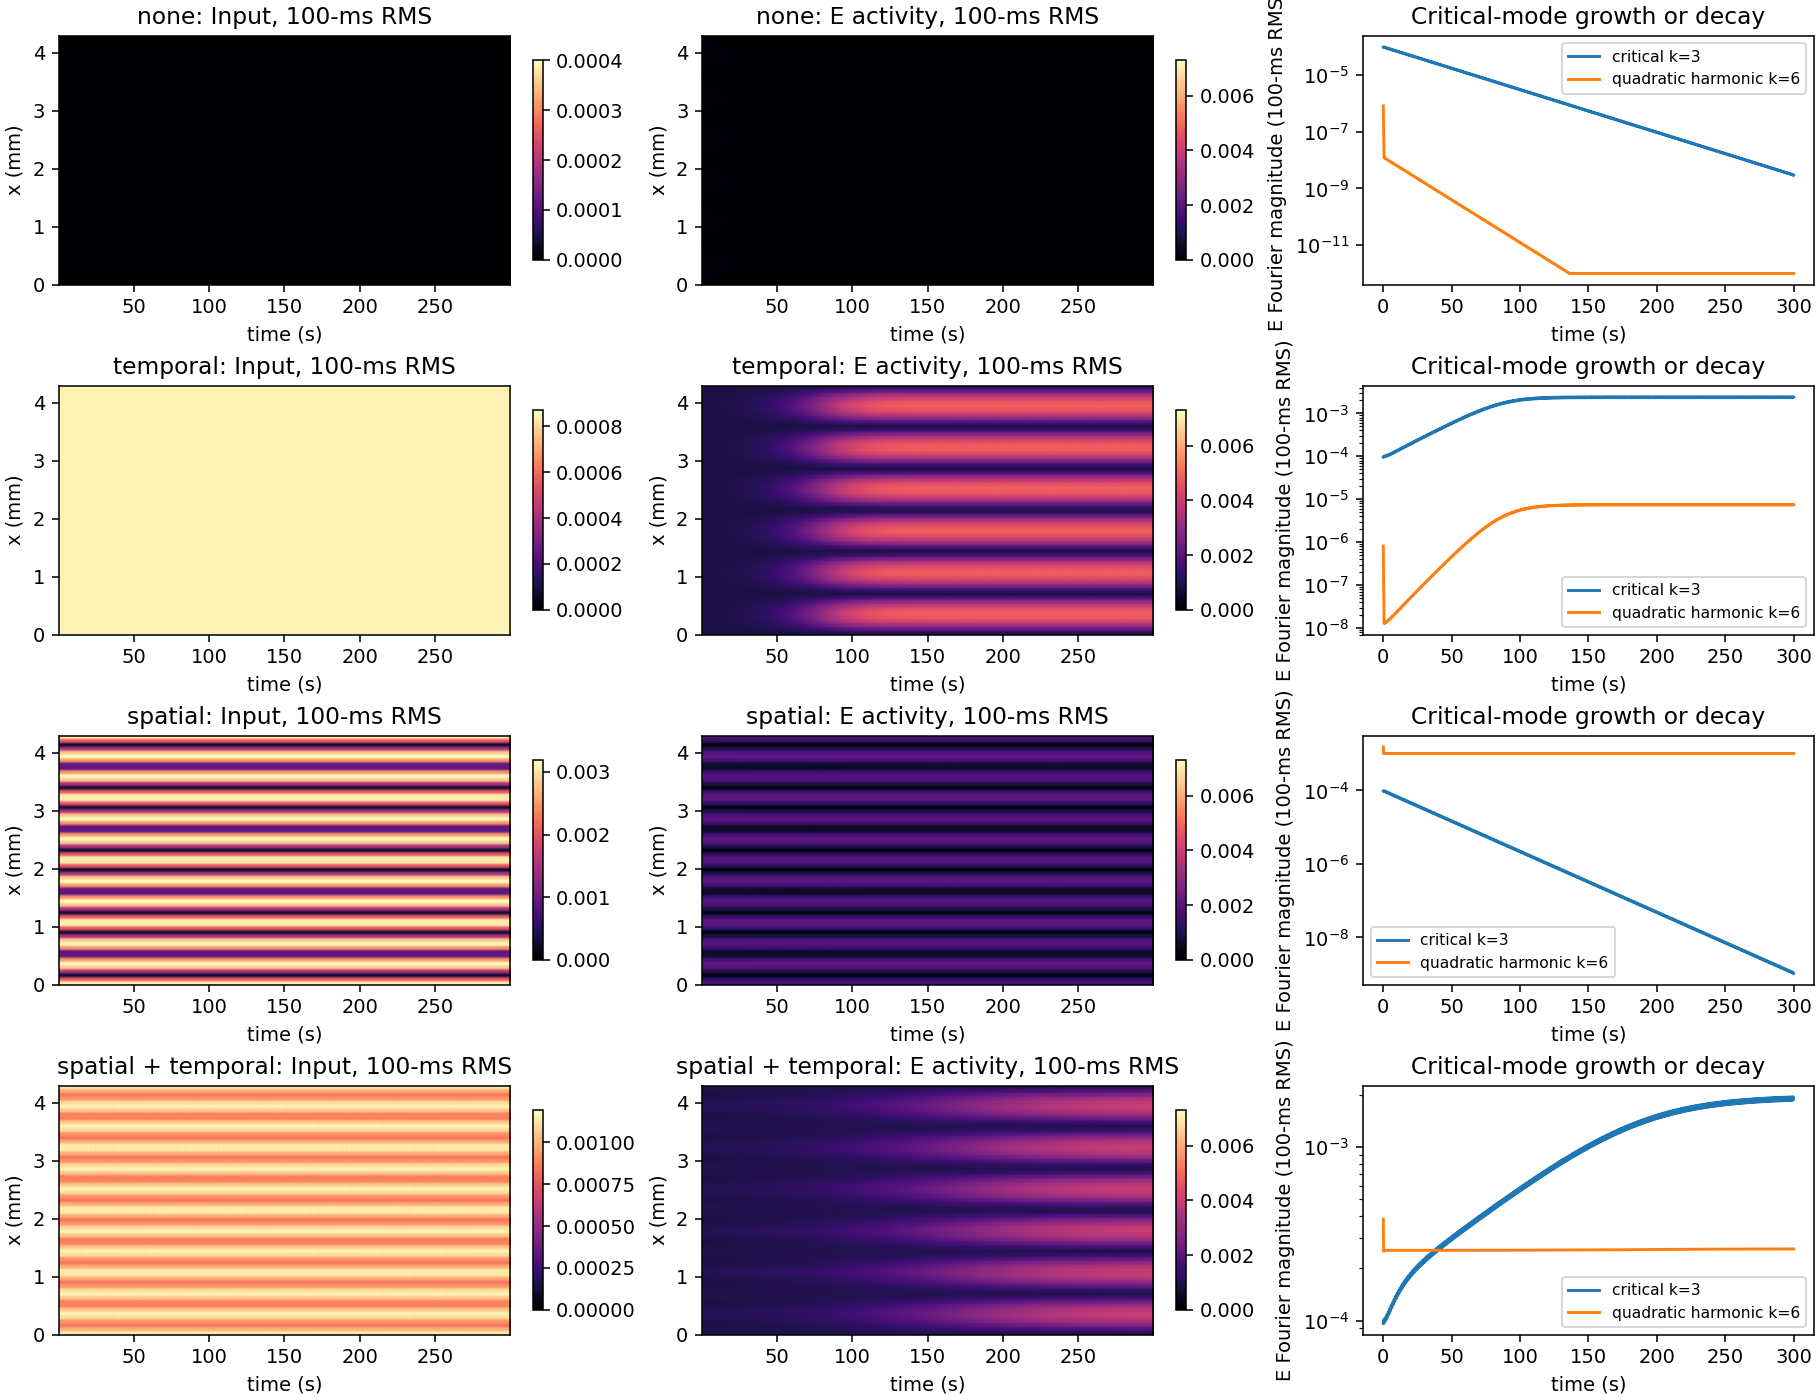

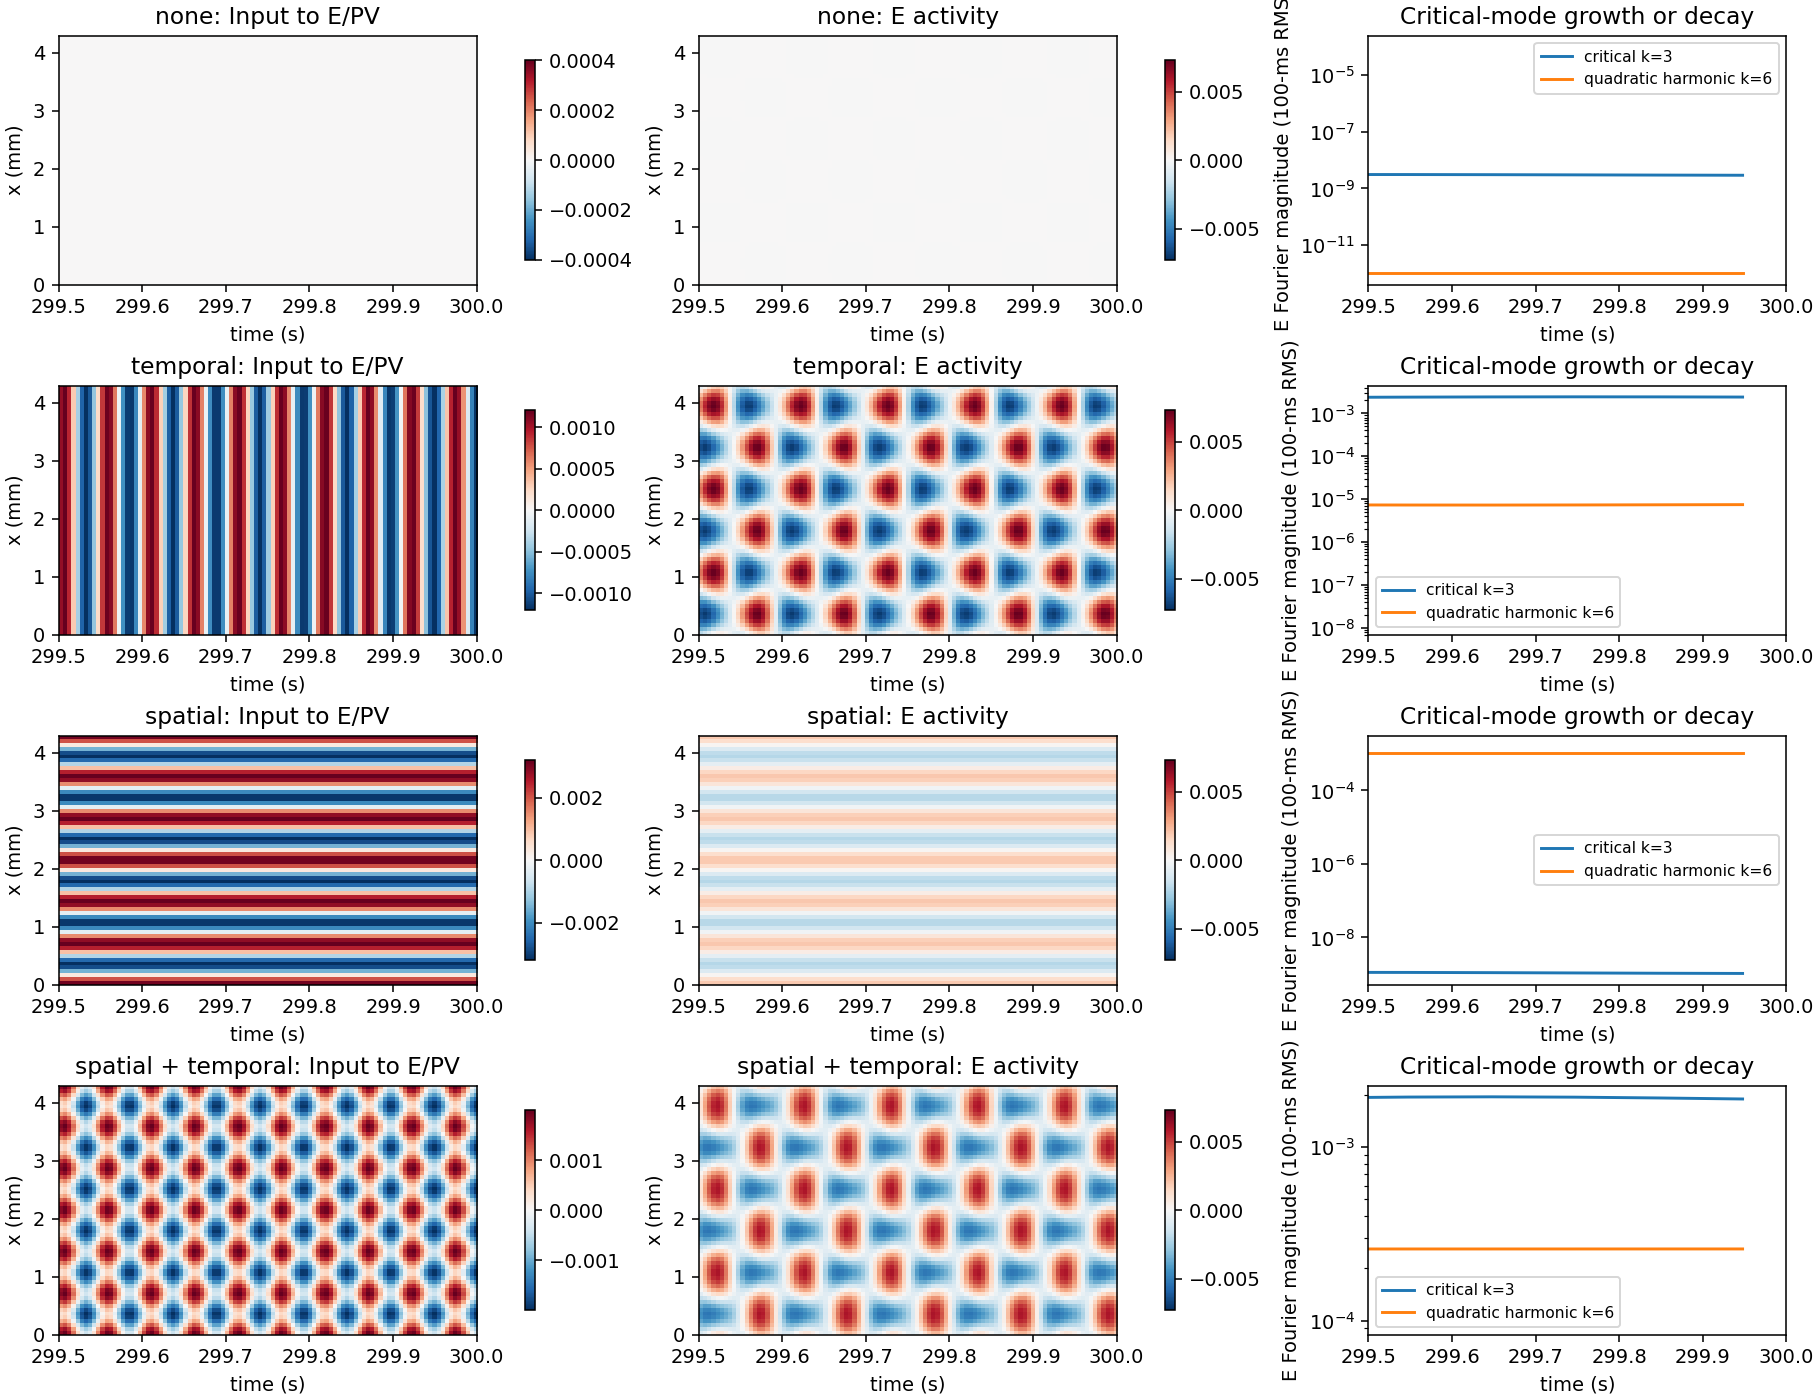

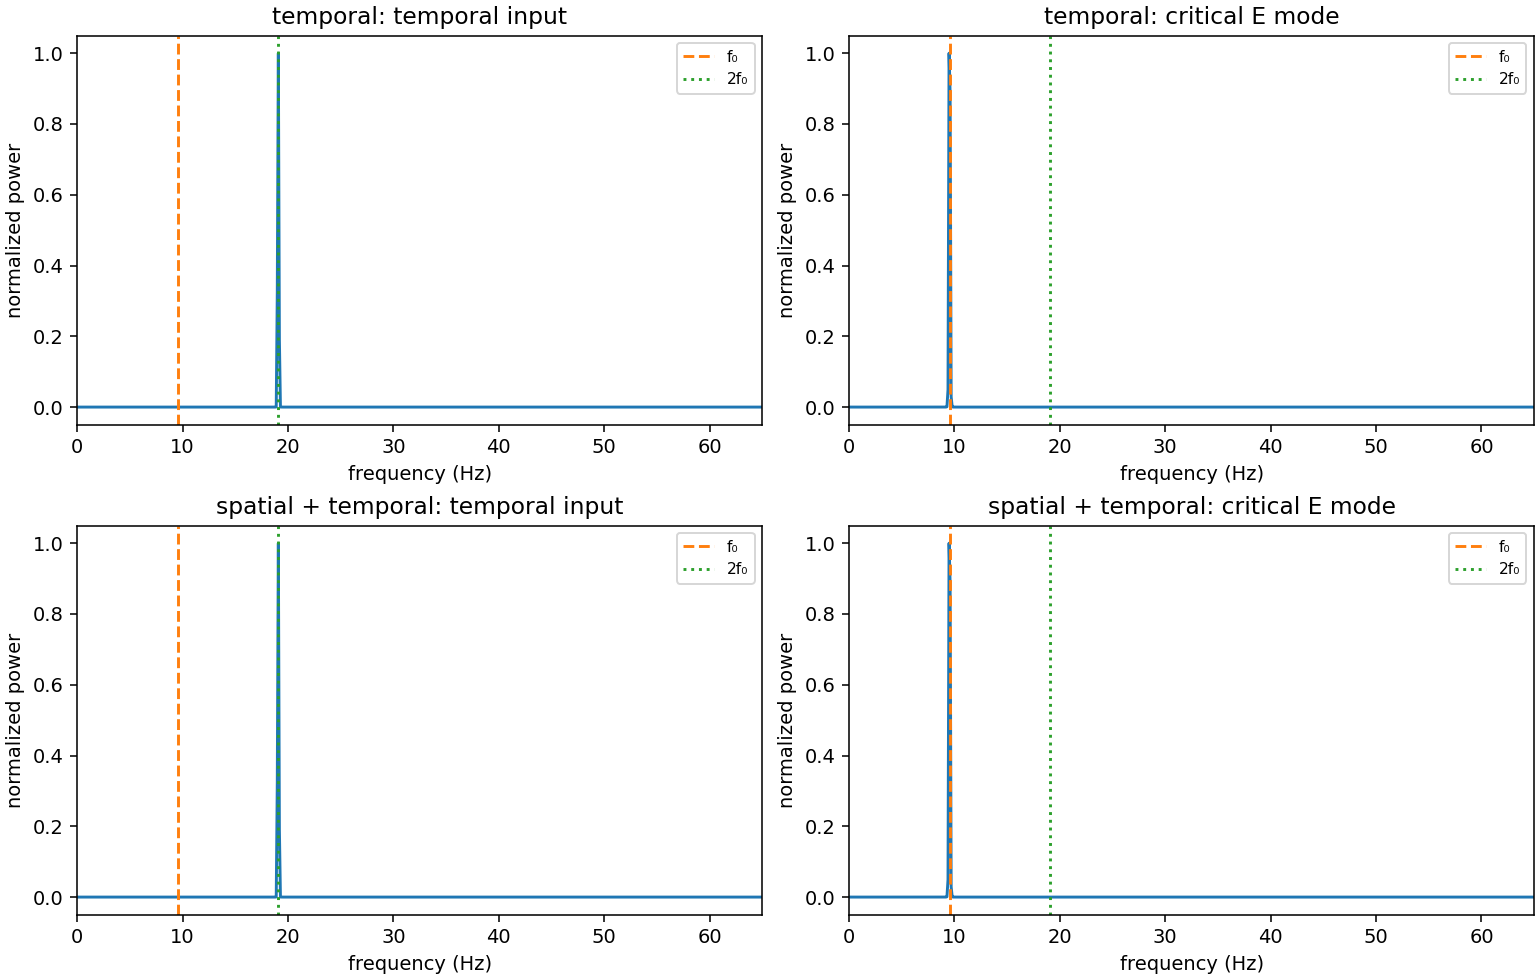

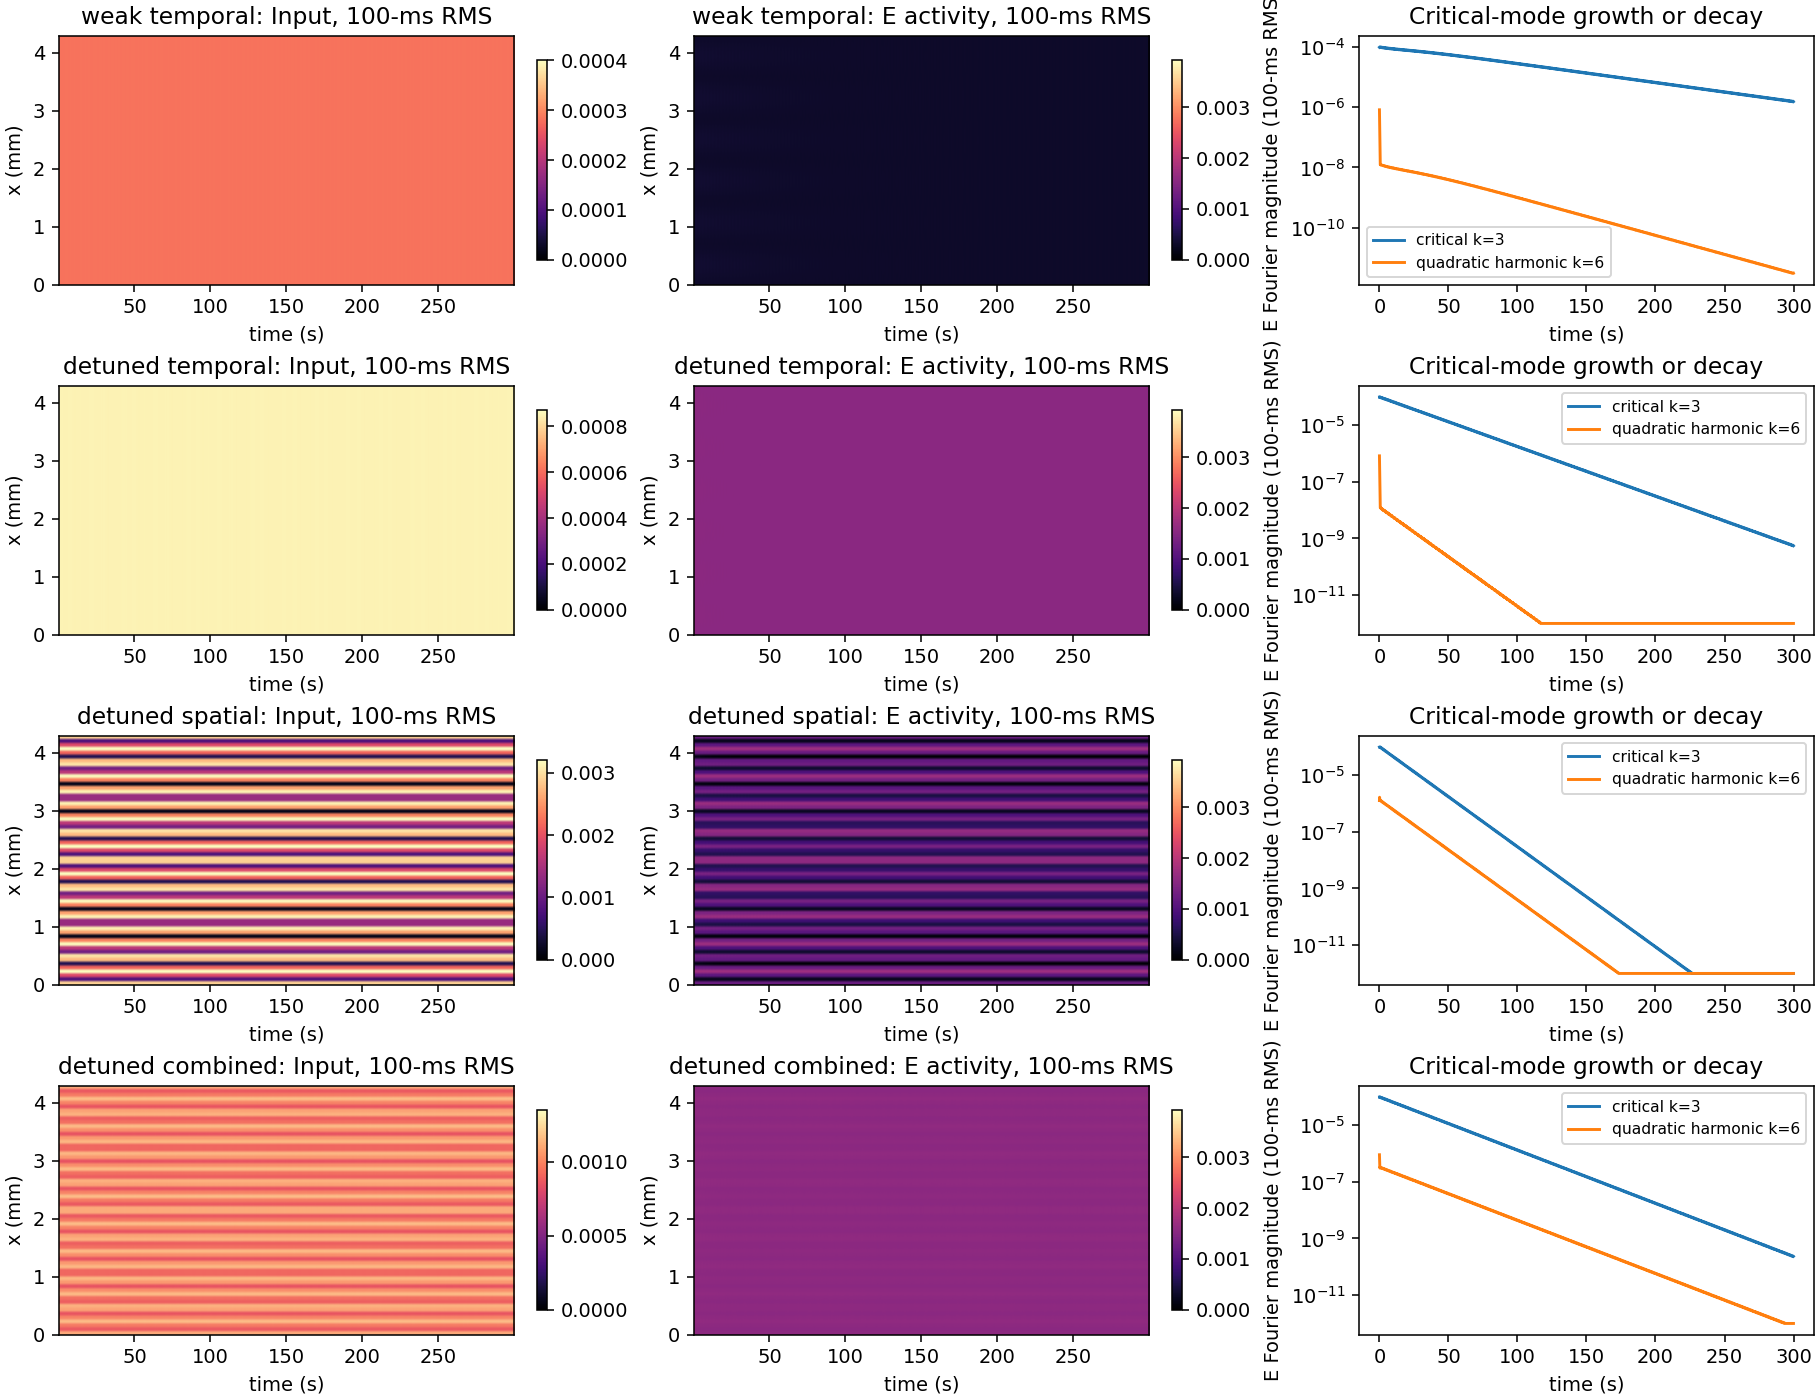

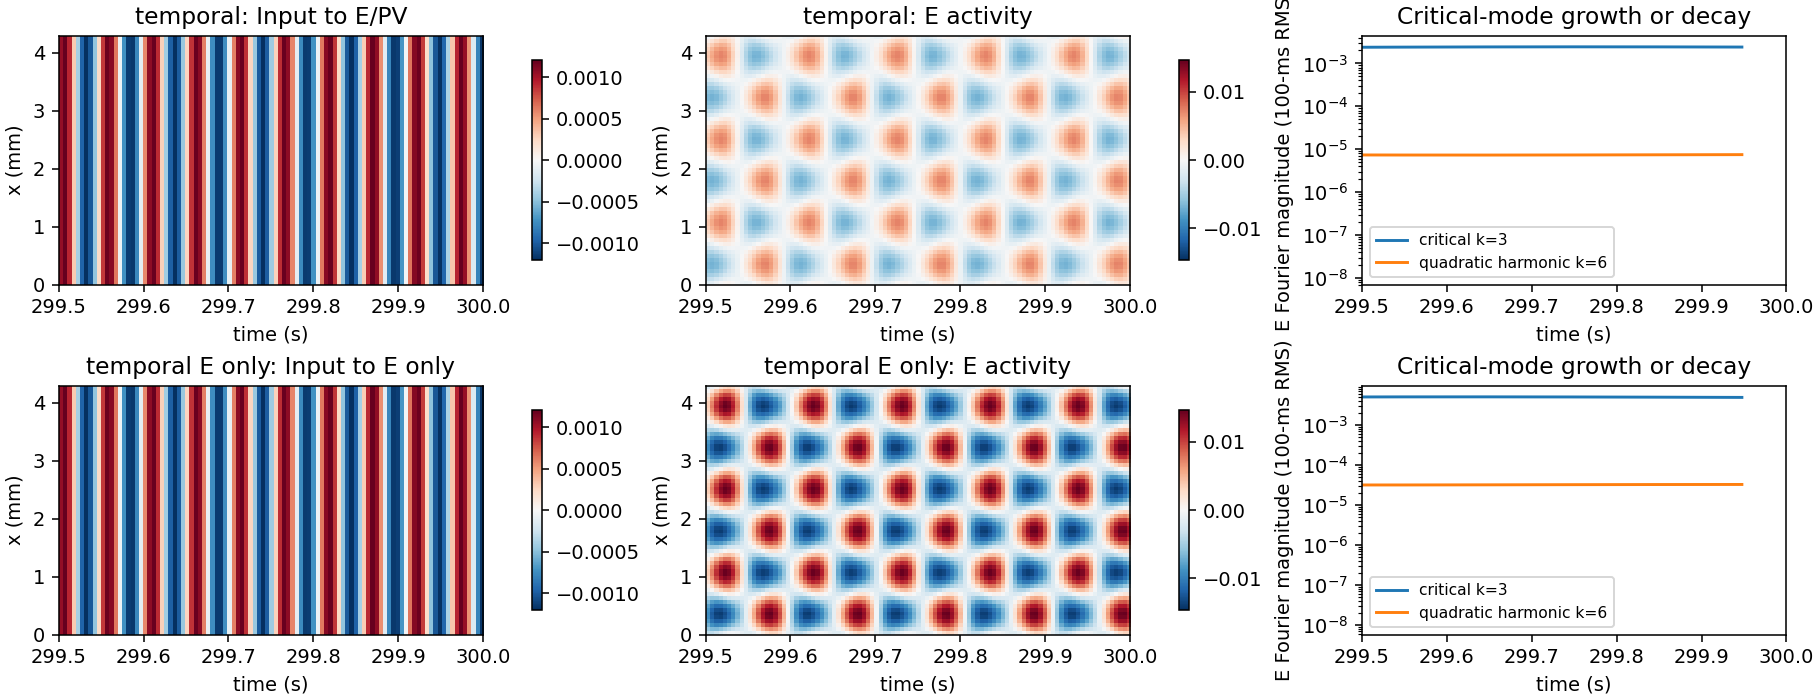

In [12]:
show3('forcing_comparison.png')
show3('forcing_comparison_late_zoom.png')
show3('frequency_doubling_verification.png')
show3('off_resonance_and_subthreshold.png')
show3('input_population_comparison.png')
print('E-only temporal threshold:',summary3['e_only_temporal_threshold'])
for label in ['none','temporal','spatial','spatial + temporal','weak temporal','detuned temporal','detuned spatial','detuned combined','temporal E only']:
    print(label,summary3['cases'][label])


### Unforced branches
Cubic-order stability is read from the signs of $\Re(c-b)$ (traveling) and $\Re(b-c)$, $\Re(b+c)$
(standing); the figure labels are computed from them. For three populations $\Re(b-c)\approx-0.007$,
so the **standing** branch is stable and the traveling branch unstable. This is the opposite of four
populations, but only marginally: $\Re b$ and $\Re c$ nearly coincide. The selection rate
$\epsilon^2\Re\alpha\,(\Re c/\Re b-1)\approx7\times10^{-8}$ ms$^{-1}$ is far too slow to act within
300 s, so both seeded runs above onset keep their initial shape and reach nearly the same amplitude.


Re(c-b) = 0.006927184644032192 ; Re(b+c) = -6.818183079857693
below onset {'kappa': 0.5876341656628891, 'p': -0.00039999999999995595, 'critical_initial': 0.0001416203310464396, 'critical_late': 7.547956621155591e-09, 'E_mode_late_rms': 5.441699236110028e-09, 'mode_frequency_hz': 9.533333333333333, 'transverse_initial': 0.0, 'transverse_final': 0.0}
standing seed above onset {'kappa': 0.588434165662889, 'p': 0.00039999999999995595, 'critical_initial': 0.0001414213562373094, 'critical_late': 0.0031245948402137767, 'E_mode_late_rms': 0.0021582492307154985, 'mode_frequency_hz': 9.533333333333333, 'transverse_initial': 0.0, 'transverse_final': 0.0}
traveling seed above onset {'kappa': 0.588434165662889, 'p': 0.00039999999999995595, 'critical_initial': 0.0002, 'critical_late': 0.003122786315691491, 'E_mode_late_rms': 0.002157135862528789, 'mode_frequency_hz': 9.533333333333333, 'transverse_initial': 0.0, 'transverse_final': 0.0}


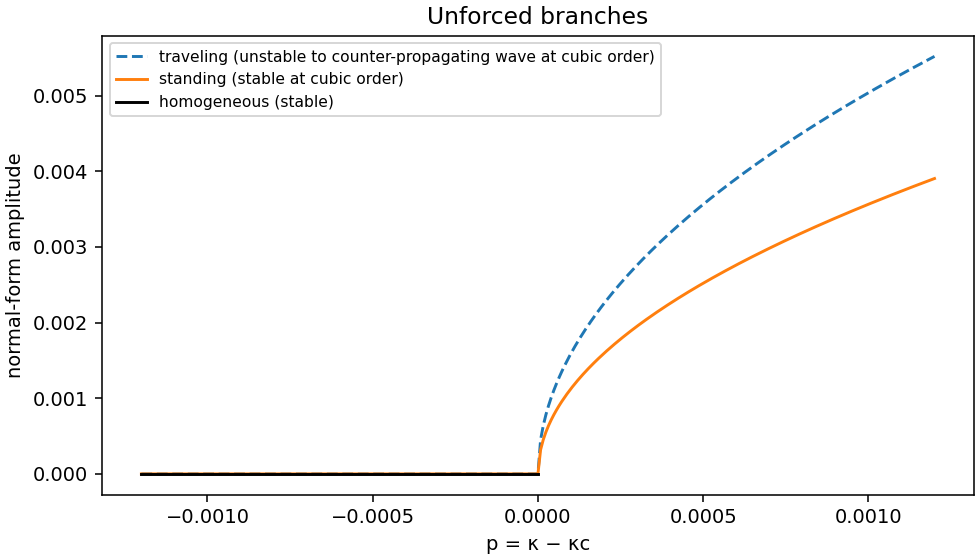

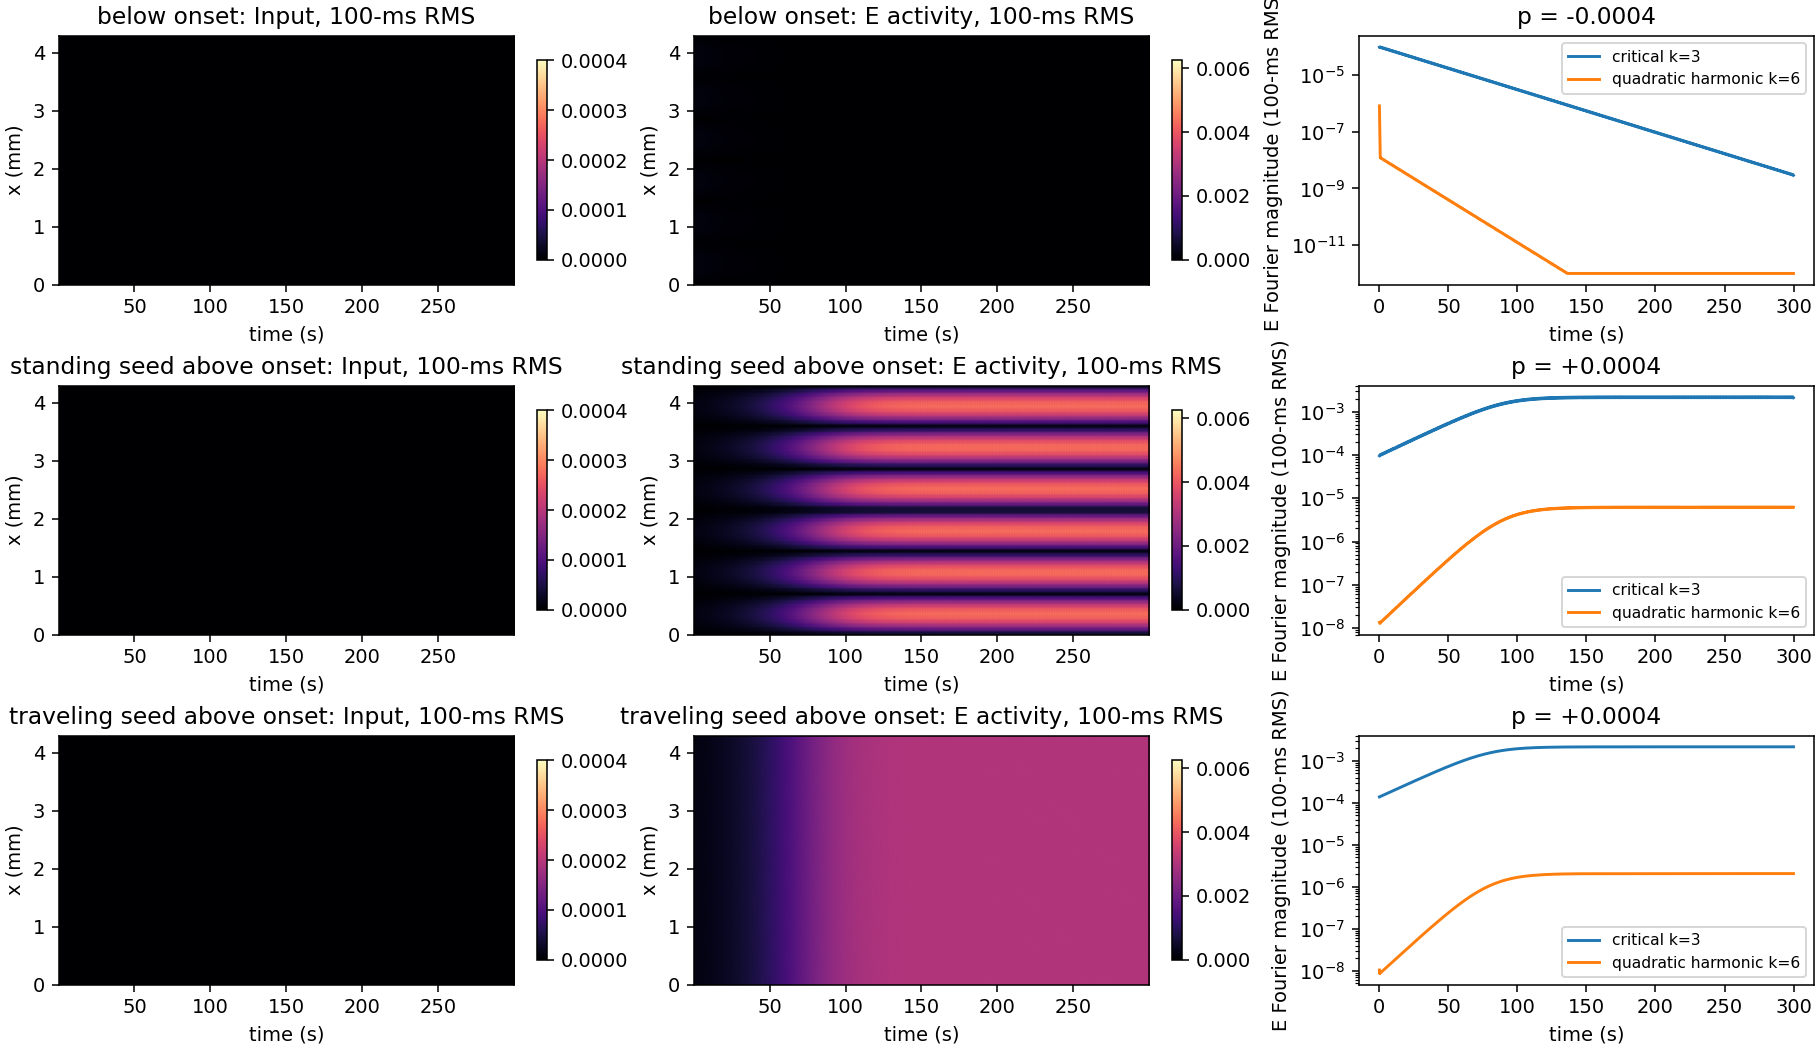

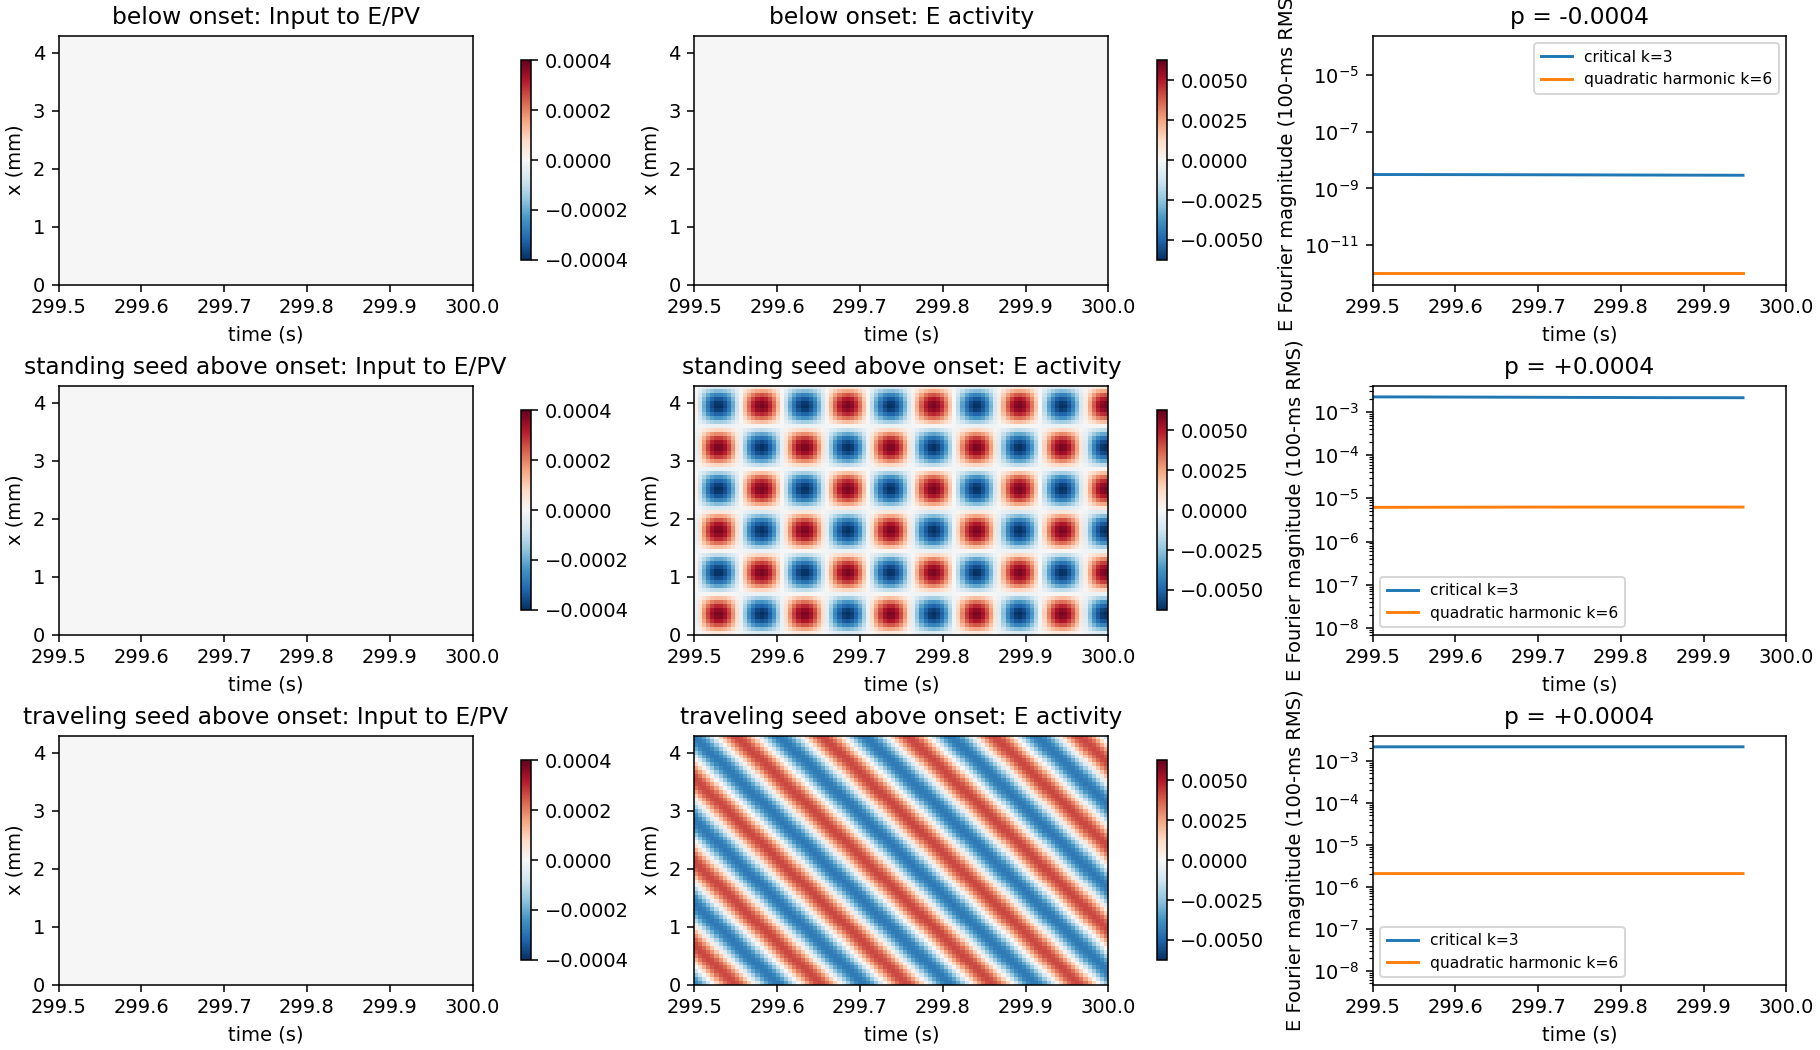

In [13]:
print('Re(c-b) =',(normal3.c-normal3.b).real,'; Re(b+c) =',(normal3.b+normal3.c).real)
show3('normal_form_branches.png')
show3('unforced_parameter_sweep.png')
show3('unforced_parameter_sweep_late_zoom.png')
for label in ['below onset','standing seed above onset','traveling seed above onset']:
    print(label,summary3['cases'][label])


### Three versus four populations
Late critical-mode amplitude (mean over the last 10% of each run) and the dominant frequency of the
critical E mode. For decayed cases the frequency is that of residual noise. The cubic predictions are
$\epsilon\sqrt{2\rho_*}$ for the temporal and combined cases. The three-population combined case is
still approaching its equilibrium at 300 s (about 94% of the cubic prediction), because its zero-state
growth rate is small. The three-population spatial-only case decays because peak 8 is below its threshold.


In [14]:
for KK,cc,ss in [(3,checks3,summary3),(4,audit(model,critical,normal,extra),summary)]:
    print(f"K={KK}: predicted temporal amplitude {EPS*np.sqrt(2*cc['temporal_rho']):.3e}, combined {EPS*np.sqrt(2*cc['combined_rho']):.3e}")
print(f"{'case':24s} {'A_late (K=3)':>13s} {'A_late (K=4)':>13s} {'f (K=3) Hz':>11s} {'f (K=4) Hz':>11s}")
for label in ['none','temporal','spatial','spatial + temporal','weak temporal','detuned temporal','detuned spatial','detuned combined','temporal E only']:
    a,b=summary3['cases'][label],summary['cases'][label]
    print(f"{label:24s} {a['critical_late']:13.3e} {b['critical_late']:13.3e} {a['mode_frequency_hz']:11.3f} {b['mode_frequency_hz']:11.3f}")


K=3: predicted temporal amplitude 3.407e-03, combined 2.897e-03
K=4: predicted temporal amplitude 2.312e-03, combined 2.174e-03
case                      A_late (K=3)  A_late (K=4)  f (K=3) Hz  f (K=4) Hz
none                         7.548e-09     9.400e-07       9.533      13.200
temporal                     3.440e-03     2.256e-03       9.533      13.200
spatial                      2.903e-09     1.875e-03       9.500      13.200
spatial + temporal           2.734e-03     2.119e-03       9.533      13.200
weak temporal                2.770e-06     5.530e-06       9.533      13.200
detuned temporal             1.551e-09     3.233e-07       9.533      13.200
detuned spatial              1.613e-14     1.147e-09       9.533      13.200
detuned combined             6.819e-10     2.139e-07       9.533      13.200
temporal E only              7.125e-03     3.820e-03       9.533      13.200


## Reproducibility and numerical limits
The parameter manifest, direct field arrays and figure files are saved under the
printed output directory. The cache fingerprint includes all model coefficients,
boundary, forcing, grid, duration, time step and seed. Setting `RECOMPUTE=True`
reruns the full simulations. The four-population matrix is fixed. The unmodified
three-population block, `make_model(3, submatrix=True)`, has a homogeneous first onset;
`make_model(3)` is the E→E-strengthened variant used in Section 7 of the 1D notebook.

`tests/test_main_analysis.py` verifies restoration of the previous coefficients,
the increasing eigenvalue derivative, cubic stability conditions, input targeting,
FFT agreement, time-step refinement and cache sensitivity. `v1_three_four_population.ipynb`
compares the three- and four-population dispersion curves with these same coefficients;
`output/v1_simple/` results use the superseded integer-gain example.
Finite-grid simulations support the mechanism; they do not replace a full
convergence or field-stability proof.
